# Share of Sales de oferta relevante e inferencia de tasas — Capital de Trabajo (IBK BdN)
Este notebook construye la base de **Share of Sales de Oferta Relevante** del proyecto
**IBK BdN (VOI)**. Esa base se cruza con la **inferencia de tasas** de la competencia
para contar con una tasa de referencia en los desembolsos perdidos. Sobre ella se estima el
**modelo de elasticidad**, que mide la sensibilidad de la efectividad a la tasa ofertada
por macroperfil, y se monitorea la estabilidad de las elasticidades con gráficos de control.

**Contenido:**
1. Altas de crédito en el sistema financiero
2. Leads del funnel comercial 
3. Cruce con variables de comportamiento del cliente y de deuda
4. Asignación de clusters (reglas de negocio de los árboles)
5. Gestión comercial de los leads
6. Desembolsos IBK y clasificación éxito / fracaso
7. Modelo de elasticidad y monitoreo de estabilidad

## 0. Imports y configuración

In [1]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

# Raíz del Drive compartido y carpetas de las bases actualizadas
cwd = r"C:/Users/Lenovo/Streaming de Google Drive/.shortcut-targets-by-id/14G2D9-Gte-83zSj-crVkwplKt-CX4FE6"
cwd2 = f"{cwd}/11_IBK BdN Cliente360/01_ Solicitud Datos/Comercial_Actualizado"
cwd3 = f"{cwd}/11_IBK BdN Cliente360/03_analisis/41_PLV 1.0/2026.10.05 V1.0/Data raw"
cwd_local = r"C:/Users/Lenovo/Desktop/IBK/2. Share of sales - Inferencia de tasas"

# Ventana de análisis (leads y desembolsos)
PERIODO_INI, PERIODO_FIN = 202503, 202609

# Código de IBK en el RCC
COD_IBK = 2

## 1. Altas de crédito en el sistema financiero

La base de altas en el Sistema Financiero registra, para cada cliente y mes, el saldo de los créditos
nuevos que tomó en cada entidad del sistema financiero (`cod_instit_financiera`). Es la
fuente que permite saber si un lead que no desembolsó en IBK sí lo hizo con la
competencia.

In [2]:
# Altas RCC en dos archivos: hasta jun-26 y de jul-26 a set-26 (el segundo trae cod_instit_financiera en mayúsculas)
df_share_ibk_1 = pd.read_excel(f"{cwd_local}/Altas_SSFF_202501_202606.xlsx")
df_share_ibk_2 = pd.read_excel(f"{cwd_local}/AG_DESEMBOLSOS_SSFF_202607_202609.xlsx")
df_share_ibk_2 = df_share_ibk_2.rename(columns={'COD_INSTIT_FINANCIERA': 'cod_instit_financiera'})

df_share_ibk = pd.concat([df_share_ibk_1, df_share_ibk_2], axis=0, ignore_index=True)
print(f"Periodos de altas: {df_share_ibk.CODMES.min()} a {df_share_ibk.CODMES.max()}")

df_share_ibk.columns = df_share_ibk.columns.str.strip().str.lower()
df_share_ibk = df_share_ibk.rename(columns={'saldo_alta_solarizado': 'saldo_alta'})
df_share_ibk = df_share_ibk[['codmes', 'key_value', 'cod_instit_financiera', 'saldo_alta']].copy()

# llave_interna: cliente-mes del alta
df_share_ibk['llave_interna'] = (
    df_share_ibk['key_value'].astype(str).str.strip()
    + '-'
    + pd.to_numeric(df_share_ibk['codmes'], errors='coerce').astype('Int64').astype(str)
)

print(f"Antes de eliminar duplicados: {df_share_ibk.shape}")
df_share_ibk = df_share_ibk.drop_duplicates().reset_index(drop=True)
print(f"Después de eliminar duplicados: {df_share_ibk.shape}")

# Control: saldo de altas por mes en S/ MM
altas_mes = (df_share_ibk.groupby('codmes')['saldo_alta'].sum() / 1e6).round(1).reset_index(name='saldo_alta_mm')
print("\nSaldo de altas RCC por mes (S/ MM):")
print(altas_mes.to_string(index=False))

Periodos de altas: 202501 a 202609
Antes de eliminar duplicados: (351297, 5)
Después de eliminar duplicados: (351266, 5)

Saldo de altas RCC por mes (S/ MM):
 codmes  saldo_alta_mm
 202501         1423.3
 202502         1413.6
 202503         1629.5
 202504         1849.8
 202505         1947.0
 202506         1925.1
 202507         1985.3
 202508         2021.5
 202509         2221.1
 202510         2308.5
 202511         2229.5
 202512         1846.0
 202601         2168.0
 202602         2138.0
 202603         2605.5
 202604         2622.0
 202605         2542.7
 202606         2505.4
 202607         2419.7
 202608         2744.4
 202609         2765.6


## 2. Leads del funnel comercial

Del funnel se toman los leads de **Capital de Trabajo** con monto ofertado, de las
campañas comerciales de interés (se excluyen programas de gobierno, vendors y
reutilizaciones), dentro de la ventana de análisis. Como un cliente puede recibir más de
una oferta en el mes, se agregan el mínimo y el máximo de tasa, monto y plazo ofertados a
nivel cliente-mes.

In [3]:
ruta = f"{cwd2}/mr_voi_funnel_leads-20261023.csv"
df_leads = pd.read_csv(ruta, sep=';')
df_leads['llave_interna'] = df_leads['key_value'] + "-" + df_leads['periodo'].astype(str)
df_leads = df_leads.drop(columns=['key_value_ruc_pn', 'cod_unico'])
df_leads['campanha'] = df_leads['campanha'].str.upper()

# Campañas de interés
campanhas = [
    'NUEVO APROBADO AGIL',
    'NUEVO APROBADO EN',
    'NUEVO PRE-APROBADO',
    'RECURRENTE ÁGIL CEM',
]

# Las campañas de interés se agrupan como "CAMPAÑA OBJETIVO"
df_leads['campanha_grupo'] = np.where(df_leads['campanha'].isin(campanhas), 'CAMPAÑA OBJETIVO', df_leads['campanha'])

# Filtro por no tener oferta
print(f"Antes del filtro de monto ofertado: {df_leads.shape}")
df_leads = df_leads[~df_leads.monto_ofertado_cmp.isna()]
print(f"Después del filtro de monto ofertado: {df_leads.shape}")

# Se agrega el min/max de tasa, monto y plazo ofertados a nivel cliente-producto-campaña-mes
df_cruce = df_leads.groupby(['llave_interna', 'producto', 'campanha_grupo', 'periodo']).agg(
    conteo=('key_value', 'count'),
    tasa_min=('tasa_piso_ofertado_cmp', 'min'),
    tasa_max=('tasa_piso_ofertado_cmp', 'max'),
    monto_min=('monto_ofertado_cmp', 'min'),
    monto_max=('monto_ofertado_cmp', 'max'),
    plazo_min=('plazo_ofertado_cmp', 'min'),
    plazo_max=('plazo_ofertado_cmp', 'max'),
).reset_index()
print(f"\nLeads agregados (todos los productos y campañas): {df_cruce.shape}")

# Solo Capital de Trabajo, campañas de interés y ventana de análisis
df_cruce = df_cruce[
    (df_cruce.producto == 'CAPITAL DE TRABAJO')
    & (df_cruce.campanha_grupo == 'CAMPAÑA OBJETIVO')
    & (df_cruce.periodo.between(PERIODO_INI, PERIODO_FIN))
].copy()
print(f"Leads de oferta relevante CT {PERIODO_INI}-{PERIODO_FIN}: {df_cruce.shape}")

# Control: leads únicos por periodo
df_cruce.groupby('periodo')['llave_interna'].nunique().reset_index(name='num_leads')

Antes del filtro de monto ofertado: (3368451, 12)
Después del filtro de monto ofertado: (3366840, 12)

Leads agregados (todos los productos y campañas): (3127380, 11)
Leads de oferta relevante CT 202503-202609: (1457384, 11)


,periodo,num_leads
0,202503,42807
1,202504,59197
2,202505,52932
3,202506,71029
4,202507,89794
5,202508,88187
6,202509,103736
7,202510,102762
8,202511,98494
9,202512,89036


## 3. Cruce con variables de comportamiento del cliente y de deuda

Se agregan las variables de comportamiento del cliente (ventas, pasivos, Izipay,
utilidad) y la deuda en el sistema financiero. Las **variables cliente** se toman con la
foto del **mes anterior** al lead, que
es la información disponible al armar la campaña. Las **variables de deuda** se toman del
mismo mes del lead, porque esa base ya incorpora el rezago y refleja la información
disponible al armar la campaña. 

In [4]:
ruta_clientes_actual = f"{cwd2}/mr_voi_tabla_clientes-20261023.csv"

cols_clientes_actual = [
    'codmes', 'key_value', 'segmento_abc', 'sei_mcdo', 'departamento',
    'antiguedad_empresa', 'nivel_ventas',
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'salprom_creditos_u03m', 'salprom_creditos_u06m', 'salprom_creditos_u12m',
    'antiguedad_izipay',
    'flag_izipay_u03m', 'flag_izipay_u06m', 'flag_izipay_u12m',
    'vol_izipay_u03m', 'vol_izipay_u06m', 'vol_izipay_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m',
]

cols_rcc_actual = [
    'codmes', 'key_value',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'avg_deuda_directa_vig_ibk_sf_u03m', 'avg_deuda_directa_vig_ibk_sf_u06m', 'avg_deuda_directa_vig_ibk_sf_u12m',
    'avg_deuda_directa_vig_total_sf_u03m', 'avg_deuda_directa_vig_total_sf_u06m', 'avg_deuda_directa_vig_total_sf_u12m',
]

df_vars_v2_clientes = pd.read_csv(ruta_clientes_actual, usecols=cols_clientes_actual, encoding='latin-1', na_values=[r'\N'], sep=';')
df_vars_v2_rcc = pd.read_csv(ruta_clientes_actual, usecols=cols_rcc_actual, encoding='latin-1', na_values=[r'\N'], sep=';')
df_vars_v2_clientes = df_vars_v2_clientes.drop_duplicates(subset=['key_value', 'codmes'])
df_vars_v2_rcc = df_vars_v2_rcc.drop_duplicates(subset=['key_value', 'codmes'])


# Variables cliente: foto del mes anterior al lead (codmes + 1 = periodo del lead)
df_vars_v2_clientes['codmes_2'] = (
    pd.to_datetime(df_vars_v2_clientes['codmes'].astype(str), format='%Y%m') + pd.DateOffset(months=1)
).dt.strftime('%Y%m').astype(int)
df_vars_v2_clientes['llave_interna'] = df_vars_v2_clientes['key_value'] + "-" + df_vars_v2_clientes['codmes_2'].astype(str)

# RCC: mismo mes del lead, sin rezago adicional
df_vars_v2_rcc['llave_interna'] = df_vars_v2_rcc['key_value'] + "-" + df_vars_v2_rcc['codmes'].astype(str)

# Base = variables cliente
df_vars_final = df_vars_v2_clientes.merge(
    df_vars_v2_rcc.drop(columns=['codmes', 'key_value']), on='llave_interna', how='left'
)
print(f"Tabla de variables cliente + RCC: {df_vars_final.shape}")

Tabla de variables cliente + RCC: (3738037, 36)


In [5]:
print(f"Antes del cruce: {df_cruce.shape}")
df_cruce = pd.merge(df_cruce, df_vars_final.drop(columns=['key_value']), on='llave_interna', how='left')
print(f"Después del cruce: {df_cruce.shape}")

# Leads sin foto de variables cliente
print(f"\nAntes del filtro cliente: {df_cruce.shape}")
df_cruce = df_cruce[df_cruce['codmes_2'].notna()].copy()
print(f"Después del filtro cliente: {df_cruce.shape}")

Antes del cruce: (1457384, 11)
Después del cruce: (1457384, 45)

Antes del filtro cliente: (1457384, 45)
Después del filtro cliente: (439033, 45)


### Tratamiento de missings

Las variables de **pasivos, deuda y utilidad** se imputan con 0 porque un registro vacío
en la tabla de clientes indica que el cliente no tiene ese saldo, no que el dato sea
desconocido. La **antigüedad de la empresa** y el **nivel de ventas** se imputan con los
valores típicos de la base (moda y mediana) calculados en el desarrollo de la segmentación,
que quedan fijos como constantes para que la asignación de clusters sea reproducible.

In [6]:
# Valores de imputación fijados en el desarrollo de la segmentación
ANTIGUEDAD_IMPUTACION = 4            # moda de antiguedad_empresa
NIVEL_VENTAS_IMPUTACION = 742771.98  # mediana de nivel_ventas

# Variables que se imputan con 0 cuando no hubo match (sin actividad registrada)
cols_fill_zero = [
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m',
]
df_cruce[cols_fill_zero] = df_cruce[cols_fill_zero].fillna(0)
df_cruce['antiguedad_empresa'] = df_cruce['antiguedad_empresa'].fillna(ANTIGUEDAD_IMPUTACION)
df_cruce['nivel_ventas'] = df_cruce['nivel_ventas'].fillna(NIVEL_VENTAS_IMPUTACION)

# SOW de deuda: proporción de la deuda vigente del cliente que está en IBK (vacío = sin historial)
df_cruce['sow_deuda_u12m'] = df_cruce['deuda_directa_vig_ibk_sf_u12m'] / df_cruce['deuda_directa_vig_total_sf_u12m']
print(f"Leads sin historial de deuda (SOW u12m vacío): {df_cruce['sow_deuda_u12m'].isna().sum():,}")

Leads sin historial de deuda (SOW u12m vacío): 246,749


### Cruce con las altas RCC

Cada lead se cruza con las altas del mismo cliente-mes. Se descartan los leads sin plazo ofertado, que no
corresponden a una oferta válida.

In [7]:
print(f"Antes del cruce con altas RCC: {df_cruce.shape}")
df_cruce = pd.merge(df_cruce, df_share_ibk.drop(columns=['codmes', 'key_value']), on='llave_interna', how='left')
print(f"Después del cruce con altas RCC: {df_cruce.shape}")

# Leads sin plazo ofertado (sin oferta válida)
print(f"\nAntes del filtro de plazo ofertado: {df_cruce.shape}")
df_cruce = df_cruce[~df_cruce.plazo_min.isna()].copy()
print(f"Después del filtro de plazo ofertado: {df_cruce.shape}")

# Control: saldo de altas de los leads por periodo en S/ MM
altas_leads = (df_cruce.groupby('periodo')['saldo_alta'].sum() / 1e6).round(1).reset_index(name='saldo_alta_mm')
print("\nSaldo de altas RCC de los leads por periodo (S/ MM):")
print(altas_leads.to_string(index=False))

Antes del cruce con altas RCC: (439033, 46)
Después del cruce con altas RCC: (440084, 48)

Antes del filtro de plazo ofertado: (440084, 48)
Después del filtro de plazo ofertado: (439827, 48)

Saldo de altas RCC de los leads por periodo (S/ MM):
 periodo  saldo_alta_mm
  202503           23.2
  202504           72.8
  202505           97.0
  202506          134.6
  202507          124.1
  202508          142.4
  202509          185.9
  202510          184.8
  202511          165.8
  202512          137.9
  202601          171.6
  202602          177.4
  202603          258.0
  202604          260.3
  202605          280.7
  202606          290.0
  202607          216.6
  202608          254.6
  202609          296.3


## 4. Asignación de clusters (reglas de negocio de los árboles)

Cada lead recibe el cluster de la **Segmentación Estratégica** aplicando las reglas de
los dos árboles finales: 6 clusters para clientes **con historial de deuda** (SOW u12m
no vacío) y 3 para clientes **sin historial** (SOW u12m vacío). Los cortes de cada regla
son los umbrales exactos de los árboles y se fijan como constantes para que la asignación
sea reproducible.

In [8]:
# Cortes de los árboles finales (ver notebook SEGMENTACION_FINAL)
CORTE_UAI_12M = 6930.2742                 # suma_uai_u12m
CORTE_MONTO_OFERTADO = 130300.0           # monto_min
CORTE_VENTAS_RAMA_BAJA = 1513490.75       # nivel_ventas, rama suma_uai <= corte
CORTE_VENTAS_RAMA_ALTA = 1461079.9375     # nivel_ventas, rama suma_uai > corte
CORTE_DEUDA_SF_3M = 345147.0156           # deuda_directa_vig_total_sf_u03m
CORTE_PASIVOS_3M = 12636.4668             # pasivosprom_u3m (árbol sin historial)
CORTE_VENTAS_SIN_HISTORIAL = 272536.9844  # nivel_ventas (árbol sin historial)

sow_null = df_cruce["sow_deuda_u12m"].isna()

# ÁRBOL 1: clientes CON historial de deuda (6 hojas) — suma_uai_u12m, monto_min, nivel_ventas, deuda_directa_vig_total_sf_u03m
# A -> cluster_6
cond_A = (~sow_null) & (df_cruce["suma_uai_u12m"] <= CORTE_UAI_12M) & (df_cruce["monto_min"] <= CORTE_MONTO_OFERTADO)

# B -> cluster_2
cond_B = (~sow_null) & (df_cruce["suma_uai_u12m"] <= CORTE_UAI_12M) & (df_cruce["monto_min"] > CORTE_MONTO_OFERTADO) \
    & (df_cruce["nivel_ventas"] <= CORTE_VENTAS_RAMA_BAJA) & (df_cruce["deuda_directa_vig_total_sf_u03m"] <= CORTE_DEUDA_SF_3M)

# C -> cluster_4
cond_C = (~sow_null) & (df_cruce["suma_uai_u12m"] <= CORTE_UAI_12M) & (df_cruce["monto_min"] > CORTE_MONTO_OFERTADO) \
    & (df_cruce["nivel_ventas"] <= CORTE_VENTAS_RAMA_BAJA) & (df_cruce["deuda_directa_vig_total_sf_u03m"] > CORTE_DEUDA_SF_3M)

# D -> cluster_5
cond_D = (~sow_null) & (df_cruce["suma_uai_u12m"] <= CORTE_UAI_12M) & (df_cruce["monto_min"] > CORTE_MONTO_OFERTADO) \
    & (df_cruce["nivel_ventas"] > CORTE_VENTAS_RAMA_BAJA)

# E -> cluster_1
cond_E = (~sow_null) & (df_cruce["suma_uai_u12m"] > CORTE_UAI_12M) & (df_cruce["nivel_ventas"] <= CORTE_VENTAS_RAMA_ALTA)

# F -> cluster_3
cond_F = (~sow_null) & (df_cruce["suma_uai_u12m"] > CORTE_UAI_12M) & (df_cruce["nivel_ventas"] > CORTE_VENTAS_RAMA_ALTA)

# ÁRBOL 2: clientes SIN historial de deuda (3 hojas) — pasivosprom_u3m, nivel_ventas
# G -> cluster_1_nulo
cond_G = (sow_null) & (df_cruce["pasivosprom_u3m"] <= CORTE_PASIVOS_3M) & (df_cruce["nivel_ventas"] <= CORTE_VENTAS_SIN_HISTORIAL)

# H -> cluster_2_nulo
cond_H = (sow_null) & (df_cruce["pasivosprom_u3m"] <= CORTE_PASIVOS_3M) & (df_cruce["nivel_ventas"] > CORTE_VENTAS_SIN_HISTORIAL)

# I -> cluster_3_nulo
cond_I = (sow_null) & (df_cruce["pasivosprom_u3m"] > CORTE_PASIVOS_3M)

# El orden de conds sigue el número de cluster (1..6 con deuda, 1..3 sin deuda)
conds = [cond_E, cond_B, cond_F, cond_C, cond_D, cond_A, cond_G, cond_H, cond_I]

choices = [
    "cluster_1_sow_no_nulo",
    "cluster_2_sow_no_nulo",
    "cluster_3_sow_no_nulo",
    "cluster_4_sow_no_nulo",
    "cluster_5_sow_no_nulo",
    "cluster_6_sow_no_nulo",
    "cluster_1_nulo",
    "cluster_2_nulo",
    "cluster_3_nulo",
]

df_cruce["cluster"] = np.select(conds, choices, default="sin_clasificar")

print("Distribución de clusters:")
print(df_cruce['cluster'].value_counts().reindex(choices + ['sin_clasificar']).fillna(0).astype(int).to_string())

Distribución de clusters:
cluster
cluster_1_sow_no_nulo     20719
cluster_2_sow_no_nulo     62934
cluster_3_sow_no_nulo     14520
cluster_4_sow_no_nulo     39976
cluster_5_sow_no_nulo     22396
cluster_6_sow_no_nulo     32543
cluster_1_nulo           126079
cluster_2_nulo            31542
cluster_3_nulo            89118
sin_clasificar                0


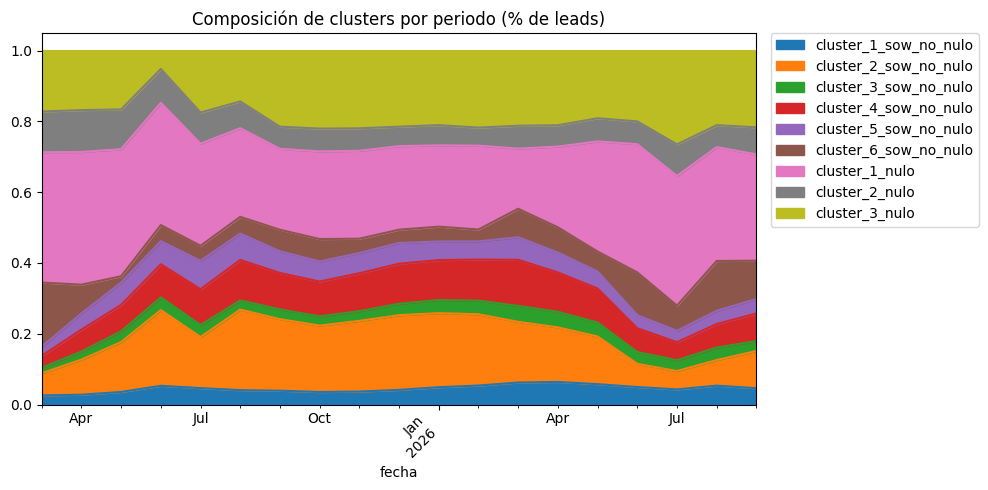

In [9]:
df_cruce['fecha'] = pd.to_datetime(df_cruce['periodo'], format='%Y%m')  # fecha real, primer día del mes

composicion = df_cruce.groupby('fecha')['cluster'].value_counts(normalize=True).unstack()[choices]

fig, ax = plt.subplots(figsize=(10, 5))
composicion.plot(kind='area', ax=ax)
ax.set_title("Composición de clusters por periodo (% de leads)")
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Gestión comercial de los leads

De las bases de gestión de leads (Capital de Trabajo, CDD y Garantizado) se obtiene el resultado
de la gestión comercial de cada cliente-mes. Las categorías se agrupan en dos: **con
gestión** (el ejecutivo contactó al cliente, cualquiera sea la respuesta) y **sin gestión**
(sin contacto, no califica o sin gestión). Si un cliente tiene varios registros en el
mes, se prioriza el que indica gestión. Esta variable distingue más adelante los fracasos
por **precio** (gestionados y perdidos) de los fracasos por **gestión** (nunca contactados).

In [10]:
rutas = [
    'mr_voi_funnel_ct-20261102.csv',
    'mr_voi_funnel_cdd-20261102.csv',
    'mr_voi_funnel_garantizado-20261102.csv',
]
usecols = ['codmes', 'producto', 'key_value', 'gestion_final']

lista_dfs = []
for ruta in rutas:
    df_gestion = pd.read_csv(f"{cwd2}/{ruta}", sep=None, engine="python", usecols=usecols)  
    print(f"{ruta}: {df_gestion.shape[0]:,} filas")
    lista_dfs.append(df_gestion)

df_gestion_final = pd.concat(lista_dfs, ignore_index=True)
df_gestion_final = df_gestion_final[~df_gestion_final.key_value.isna()]

# Agrupación de las categorías de gestión en con / sin gestión
to_replace = {
    'Gestionado': 'Con_Gestion',
    'Acepta Campaña': 'Con_Gestion',
    'Acepta Visita': 'Con_Gestion',
    'Acepta Visita RT': 'Con_Gestion',
    'No Acepta Campaña': 'Con_Gestion',
    'Desistió': 'Con_Gestion',
    'Lo Pensará': 'Con_Gestion',
    'Sin Gestión': 'Sin_Gestion',
    'Sin Contacto': 'Sin_Gestion',
    'No Califica': 'Sin_Gestion',
}
df_gestion_final['flg_gestion'] = df_gestion_final['gestion_final'].replace(to_replace)

# Un registro por cliente-mes, priorizando 'Con_Gestion'
df_gestion_final['prioridad_gestion'] = (df_gestion_final['flg_gestion'] == 'Con_Gestion').astype(int)
df_gestion_final = df_gestion_final.sort_values('prioridad_gestion', ascending=False)

print(f"\nAntes de eliminar duplicados: {df_gestion_final.shape}")
df_gestion_final = df_gestion_final.drop_duplicates(subset=['key_value', 'codmes'], keep='first')
print(f"Después de eliminar duplicados: {df_gestion_final.shape}")

df_gestion_final['llave_interna'] = df_gestion_final['key_value'] + "-" + df_gestion_final['codmes'].astype(str)
df_gestion_final = df_gestion_final[['llave_interna', 'gestion_final', 'flg_gestion']]

mr_voi_funnel_ct-20261102.csv: 1,181,137 filas
mr_voi_funnel_cdd-20261102.csv: 406,038 filas
mr_voi_funnel_garantizado-20261102.csv: 107,620 filas

Antes de eliminar duplicados: (1694746, 6)
Después de eliminar duplicados: (1692375, 6)


In [11]:
print(f"Antes del cruce con gestión: {df_cruce.shape}")
df_cruce = pd.merge(df_cruce, df_gestion_final, on='llave_interna', how='left')
print(f"Después del cruce con gestión: {df_cruce.shape}")

# Sin match de gestión = cliente sin gestión comercial en el periodo
df_cruce['flg_gestion'] = df_cruce['flg_gestion'].fillna('Sin_Gestion')
df_cruce['gestion_final'] = df_cruce['gestion_final'].fillna('Sin_Gestion')
print(df_cruce['flg_gestion'].value_counts().to_string())

Antes del cruce con gestión: (439827, 50)
Después del cruce con gestión: (439827, 52)
flg_gestion
Con_Gestion           311479
Sin_Gestion           128318
Bloqueado por Giro        28
Pendiente                  2


## 6. Desembolsos IBK y clasificación éxito / fracaso

De la base de desembolsos de originación (población de interés) se toma, para cada
cliente-mes, el desembolso de **mayor monto** en cualquier producto. Al cruzarlo con los
leads se identifica si el cliente desembolsó en IBK.

In [12]:
ruta = f"{cwd3}/mr_voi_desembolso_ejecucion-202501-202609-v1.6.csv"

usecols = ['key_value', 'periodo', 'colocacion_neta', 'campana_vpc', 'tasa_desembolso_ibk', 'canal', 'producto', 'flg_poblacion_objetivo']
df_desembolsos = pd.read_csv(ruta, usecols=usecols)

# Nombres de la base de ejecución -> nombres usados en el flujo
df_desembolsos = df_desembolsos.rename(columns={
    'colocacion_neta': 'monto_desembolsado',
    'tasa_desembolso_ibk': 'tasa_2022',
    'canal': 'canal_final',
})

# Solo población objetivo y ventana de análisis
print(f"Antes de los filtros: {df_desembolsos.shape}")
df_desembolsos = df_desembolsos[(df_desembolsos.flg_poblacion_objetivo == 1) & df_desembolsos.periodo.between(PERIODO_INI, PERIODO_FIN)]
print(f"Después de los filtros: {df_desembolsos.shape}")

# Un desembolso por cliente-periodo: el de mayor monto
print(f"\nAntes de eliminar duplicados: {df_desembolsos.shape}")
df_desembolsos = df_desembolsos.sort_values(by=['key_value', 'periodo', 'monto_desembolsado'], ascending=[False, False, False])
df_desembolsos = df_desembolsos.drop_duplicates(subset=['key_value', 'periodo'], keep='first')
print(f"Después de eliminar duplicados: {df_desembolsos.shape}")

df_desembolsos['llave_interna'] = df_desembolsos['key_value'] + "-" + df_desembolsos['periodo'].astype(str)
df_desembolsos['campana_vpc'] = df_desembolsos['campana_vpc'].str.upper()
df_desembolsos = df_desembolsos[['llave_interna', 'producto', 'campana_vpc', 'monto_desembolsado', 'tasa_2022']]

Antes de los filtros: (97767, 8)
Después de los filtros: (16818, 8)

Antes de eliminar duplicados: (16818, 8)
Después de eliminar duplicados: (16792, 8)


In [13]:
df_cruce_final = df_cruce.drop(columns=['producto', 'campanha_grupo'])

print(f"Antes del cruce con desembolsos: {df_cruce_final.shape}")
df_cruce_final = pd.merge(df_cruce_final, df_desembolsos, on='llave_interna', how='left')
print(f"Después del cruce con desembolsos: {df_cruce_final.shape}")

Antes del cruce con desembolsos: (439827, 50)
Después del cruce con desembolsos: (439827, 54)


### Monto de referencia y universo de comparación

`flg_desembolso_ibk` marca las filas donde el cliente desembolsó en IBK (monto
desembolsado positivo y entidad IBK en el RCC). El **monto de referencia**
(`delta_deuda_final`) es el monto desembolsado si fue en IBK y el saldo del alta si fue en
otra entidad. Para las altas en la competencia se exige un mínimo de S/ 50 mil, de modo
que operaciones pequeñas no cuenten como un crédito perdido.
Finalmente se excluyen las altas IBK del RCC que no aparecen en la base de desembolsos,
porque no se les puede asociar producto ni campaña.

In [14]:
MONTO_MIN_ALTA_COMPETENCIA = 50_000  # S/, alta mínima en otra entidad para contar como desembolso perdido

# Flag de desembolso IBK considerando todos los productos (no solo capital de trabajo)
df_cruce_final['flg_desembolso_ibk_all_products'] = np.where(
    (df_cruce_final['monto_desembolsado'] > 0) & (df_cruce_final['cod_instit_financiera'] == COD_IBK), 1, 0
)

# Monto de referencia: desembolsado si fue IBK, saldo del alta si fue competencia
df_cruce_final['delta_deuda_final'] = np.where(
    df_cruce_final['flg_desembolso_ibk_all_products'] == 1, df_cruce_final['monto_desembolsado'], df_cruce_final['saldo_alta']
)

# Universo: desembolsos IBK + altas en la competencia por encima del mínimo
df_cruce_1 = df_cruce_final[df_cruce_final['flg_desembolso_ibk_all_products'] == 1].copy()
df_cruce_2 = df_cruce_final[
    (df_cruce_final['flg_desembolso_ibk_all_products'] == 0) & (df_cruce_final.delta_deuda_final > MONTO_MIN_ALTA_COMPETENCIA)
].copy()

print(f"Antes del filtro de universo: {df_cruce_final.shape}")
df_cruce_final = pd.concat([df_cruce_1, df_cruce_2], axis=0).reset_index(drop=True)
print(f"Después del filtro de universo: {df_cruce_final.shape}")

# Altas IBK del RCC sin desembolso en la base de ejecución
print(f"\nAntes de excluir altas IBK sin desembolso: {df_cruce_final.shape}")
df_cruce_final = df_cruce_final[
    ~((df_cruce_final['cod_instit_financiera'] == COD_IBK) & (df_cruce_final['flg_desembolso_ibk_all_products'] == 0))
].copy()
print(f"Después de excluir altas IBK sin desembolso: {df_cruce_final.shape}")

# El producto solo aplica a desembolsos IBK
df_cruce_final.loc[df_cruce_final['flg_desembolso_ibk_all_products'] == 0, 'producto'] = np.nan

# Variables de fecha para reportes (fecha viene de la sección 4)
df_cruce_final['anio'] = df_cruce_final['fecha'].dt.year
df_cruce_final['trimestre'] = df_cruce_final['fecha'].dt.quarter
df_cruce_final['periodo_q'] = df_cruce_final['fecha'].dt.to_period('Q').astype(str)  # ej. 2025Q2

Antes del filtro de universo: (439827, 56)
Después del filtro de universo: (20620, 56)

Antes de excluir altas IBK sin desembolso: (20620, 56)
Después de excluir altas IBK sin desembolso: (19462, 56)


### Clasificación del resultado del lead

Cada fila se clasifica en una de cinco categorías. El **éxito** es un desembolso IBK de
Capital de Trabajo en una campaña de interés. Los **fracasos** se distinguen según dónde
y cuánto desembolsó el cliente: en IBK con otro producto, en la competencia por un monto
**similar** al ofertado (hasta 120% del monto mínimo ofertado), separando si el lead fue
gestionado o no, o en la competencia por un monto claramente **mayor** (más de 120%), que
no se considera comparable con la oferta.

In [15]:
RATIO_MONTO_SIMILAR = 1.2 

# Categorías de resultado 
EXITO = 'exito_desembolso_ibk_ct'
FRACASO_IBK_OTRO = 'fracaso_desembolso_ibk_no_ct'
FRACASO_SIMILAR_CON_GESTION = 'fracaso_desembolso_no_ibk_monto_similar_con_gestion'
FRACASO_SIMILAR_SIN_GESTION = 'fracaso_desembolso_no_ibk_monto_similar_sin_gestion'
FRACASO_MONTO_MAYOR = 'fracaso_desembolso_no_ibk_monto_distinto_mayor_120'

es_ibk = df_cruce_final['flg_desembolso_ibk_all_products'] == 1
ratio_monto = df_cruce_final['delta_deuda_final'] / df_cruce_final['monto_min']

# 1 éxito CT en campaña de interés | 2 IBK otro producto | 3.1 / 3.2 competencia monto similar con / sin gestión | 4 competencia monto mayor
cond_1 = es_ibk & (df_cruce_final["producto"] == 'CAPITAL DE TRABAJO') & (df_cruce_final["campana_vpc"].isin(campanhas))
cond_2 = es_ibk & (~df_cruce_final["producto"].isna())
cond_3_1 = ~es_ibk & (df_cruce_final["producto"].isna()) & (ratio_monto <= RATIO_MONTO_SIMILAR) & (df_cruce_final['flg_gestion'] == 'Con_Gestion')
cond_3_2 = ~es_ibk & (df_cruce_final["producto"].isna()) & (ratio_monto <= RATIO_MONTO_SIMILAR) & (df_cruce_final['flg_gestion'] != 'Con_Gestion')
cond_4_1 = ~es_ibk & (df_cruce_final["producto"].isna()) & (ratio_monto > RATIO_MONTO_SIMILAR)

conds = [cond_1, cond_2, cond_3_1, cond_3_2, cond_4_1]
choices = [EXITO, FRACASO_IBK_OTRO, FRACASO_SIMILAR_CON_GESTION, FRACASO_SIMILAR_SIN_GESTION, FRACASO_MONTO_MAYOR]

df_cruce_final["flg_exito_4"] = np.select(conds, choices, default="sin_clasificar")

print("Distribución del resultado de los leads:")
print(df_cruce_final["flg_exito_4"].value_counts().to_string())

Distribución del resultado de los leads:
flg_exito_4
exito_desembolso_ibk_ct                                6454
fracaso_desembolso_no_ibk_monto_similar_con_gestion    5505
fracaso_desembolso_no_ibk_monto_similar_sin_gestion    4416
fracaso_desembolso_no_ibk_monto_distinto_mayor_120     1995
fracaso_desembolso_ibk_no_ct                           1092


## 7. Modelo de sensibilidad

Con la base de oferta relevante se estima la **elasticidad de la efectividad respecto a la
tasa ofertada** por macroperfil: cuánto cae el monto desembolsado sobre el monto ofertado
cuando sube la tasa. Los 9 clusters se agrupan en 4 **macroperfiles** para tener
materialidad mensual suficiente. Se construye un panel macroperfil × mes, se estima un
modelo de efectos fijos con ventanas acumulativas (may-26 a set-26) y se monitorea la
estabilidad de las elasticidades con gráficos de control I-MR.

### Funciones de gráficos

Helpers de estilo ejecutivo y los seis gráficos que usa la sección: materialidad mensual,
mix por macroperfil, evolutivo tasa-efectividad, nube de puntos tasa-efectividad, heatmap
de significancia y evolutivo de elasticidades.

In [16]:
from matplotlib.patches import FancyBboxPatch, Patch
import matplotlib.colors as mcolors
import math

COLOR_TITULO = '#1D4290'
PALETA_15 = [
    '#E37222', '#329262', '#1D4290', '#8B0000', '#E69F00',
    '#0072B2', '#D55E00', '#CC79A7', '#56B4E9', '#009E73',
    '#27D75A', '#332288', '#117733', '#CC6677', '#AA4499',
]
PALETA_100 = PALETA_15 + [mcolors.to_hex(plt.get_cmap('turbo')(i)) for i in np.linspace(0, 1, 85)]  # paleta extendida
MESES_ES = {
    1: 'Ene',
    2: 'Feb',
    3: 'Mar',
    4: 'Abr',
    5: 'May',
    6: 'Jun',
    7: 'Jul',
    8: 'Ago',
    9: 'Sep',
    10: 'Oct',
    11: 'Nov',
    12: 'Dic',
}


# ---------- helpers ----------
def _aplicar_estilo_ejecutivo(ax, titulo, ylabel, color_titulo='#1D4290', rotacion_x=90):
    ax.set_title(titulo, fontsize=11, fontweight='bold', color=color_titulo, pad=15)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=9, fontweight='bold', color=color_titulo)
    ax.tick_params(axis='x', rotation=rotacion_x, labelsize=8, labelcolor='black')
    ax.tick_params(axis='y', labelsize=8, labelcolor='black')
    ax.grid(True, axis='y', linestyle='--', alpha=0.3, color='gray')

    for spine in ['top', 'right', 'bottom', 'left']:
        ax.spines[spine].set_visible(False)


def _formatear_periodo_str(periodo_val):
    """Convierte un periodo YYYYMM (numérico o string) a formato 'Ene '25'."""
    p_str = str(int(periodo_val)) if pd.notnull(periodo_val) else ''
    if len(p_str) == 6:
        anio = p_str[2:4]
        mes_num = int(p_str[4:6])
        meses_es = {
            1: 'Ene',
            2: 'Feb',
            3: 'Mar',
            4: 'Abr',
            5: 'May',
            6: 'Jun',
            7: 'Jul',
            8: 'Ago',
            9: 'Sep',
            10: 'Oct',
            11: 'Nov',
            12: 'Dic',
        }
        mes_str = meses_es.get(mes_num, p_str[4:6])
        return f"{mes_str} '{anio}"
    return p_str


def _formatear_etiqueta_valor(valor, es_monto=True):
    """Formatea el valor de la barra: si es monto y supera el millón, usa escala MM.

    Ej: 3,400,000 -> 3.4 MM. Si es un número (N) o valor menor, usa formato
    estándar con comas.
    """
    if es_monto and abs(valor) >= 1_000_000:
        return f'{valor / 1_000_000:.1f} MM'
    elif abs(valor) >= 1_000:
        return f'{valor:,.0f}'.replace(',', ' ')
    else:
        return f'{valor:,.1f}' if isinstance(valor, float) else f'{valor:,}'


def _escalar_serie(s):
    s_clean = s.dropna()
    if not s_clean.empty and s_clean.max() <= 1.0:
        return s * 100, '%'
    return s, ''


def _formatear_periodos_panel(df, columna_periodo):
    sub_df = df.copy()
    meses = {
        1: 'Ene',
        2: 'Feb',
        3: 'Mar',
        4: 'Abr',
        5: 'May',
        6: 'Jun',
        7: 'Jul',
        8: 'Ago',
        9: 'Sep',
        10: 'Oct',
        11: 'Nov',
        12: 'Dic',
    }
    sub_df['periodo_label'] = sub_df[columna_periodo].apply(
        lambda x: f"{meses[int(x) % 100]}' {str(int(x) // 100)[-2:]}"
    )
    return sub_df


# ---------- gráficos ----------
def plot_materialidad_por_mes(
    df,
    col_periodo='periodo',
    col_valor='valor',
    titulo='Evolución Mensual',
    ylabel='Valor',
    color_barras='#1D4290',  # Azul ejecutivo por defecto
    color_titulo='#1D4290',
    rotacion_x=0,  # Horizontal por defecto para meses cortos
    es_monto=True,  # True para escalar a MM si supera el millón
):
    # Copia para no alterar el DataFrame original
    df_plot = df.copy()

    # Ordenar cronológicamente por periodo
    df_sorted = df_plot.sort_values(by=col_periodo, ascending=True)

    # Generar etiquetas de meses (ej: 202401 -> "Ene '24")
    etiquetas_x = [_formatear_periodo_str(p) for p in df_sorted[col_periodo]]

    fig, ax = plt.subplots(figsize=(9, 4))

    barras = ax.bar(
        np.arange(len(df_sorted)),
        df_sorted[col_valor].values,
        width=0.55,
        color=color_barras,
        edgecolor='black',
        linewidth=0.6,
        alpha=0.9,
    )

    ax.set_xticks(np.arange(len(df_sorted)))
    ax.set_xticklabels(etiquetas_x)

    # Margen superior dinámico para las etiquetas
    ax.set_ylim(0, df_sorted[col_valor].max() * 1.18)

    # Añadir etiquetas dinámicas sobre cada barra
    for barra, valor in zip(barras, df_sorted[col_valor]):
        texto_etiqueta = _formatear_etiqueta_valor(valor, es_monto=es_monto)

        ax.annotate(
            texto_etiqueta,
            (barra.get_x() + barra.get_width() / 2, valor),
            xytext=(0, 6),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=7.5,
            color='black',
            bbox=dict(boxstyle='round,pad=0.22', fc='#F4F6F7', ec='none', alpha=0.9),
        )

    # Aplicar la línea estética ejecutiva
    _aplicar_estilo_ejecutivo(
        ax,
        titulo,
        ylabel,
        color_titulo=color_titulo,
        rotacion_x=rotacion_x,
    )

    plt.tight_layout()
    plt.show()


def plot_participacion_panel(
    df,
    columna_periodo='periodo',
    columna_grupo='cluster_comercial',
    metrica_materialidad='desembolsos',
    titulo=None,
    paleta=PALETA_100,
):
    if df.empty:
        print('El DataFrame no contiene registros para graficar')
        return

    sub_df = _formatear_periodos_panel(df, columna_periodo)

    df_pivot = sub_df.pivot(index=columna_periodo, columns=columna_grupo, values=metrica_materialidad).fillna(0)
    df_pct = df_pivot.div(df_pivot.sum(axis=1), axis=0) * 100

    periodos_unicos = df_pct.index.tolist()
    x = np.arange(len(periodos_unicos))

    labels_periodo = (
        sub_df.drop_duplicates(columna_periodo).set_index(columna_periodo).loc[periodos_unicos]['periodo_label'].values
    )

    fig, ax = plt.subplots(figsize=(10, 5.2))
    grupos = df_pct.columns.tolist()

    bottom = np.zeros(len(periodos_unicos))
    for i, grupo in enumerate(grupos):
        color = paleta[i % len(paleta)]
        valores = df_pct[grupo].values

        ax.bar(x, valores, bottom=bottom, width=0.65, color=color, label=str(grupo), edgecolor='white', linewidth=0.5)
        bottom += valores

    ax.set_xticks(x)
    ax.set_xticklabels(labels_periodo)
    ax.set_xlabel('Periodo', fontsize=9, fontweight='bold', color='#1D4290')
    ax.set_ylabel('Participación (%)', fontsize=9, fontweight='bold', color='#1D4290')
    ax.tick_params(axis='both', labelsize=8, labelcolor='black')
    ax.tick_params(axis='x', rotation=90)

    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.0f}%'))

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3, color='gray')

    # Leyenda abajo en columnas
    num_cols = min(len(grupos), 4)
    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.22),
        ncol=num_cols,
        frameon=True,
        facecolor='white',
        edgecolor='lightgray',
        fontsize=8,
    )

    titulo = (
        titulo
        or f'Mix de {metrica_materialidad.replace("_", " ").capitalize()} por {columna_grupo.replace("_", " ").capitalize()} (%)'
    )
    ax.set_title(titulo, fontsize=11, fontweight='bold', color='#1D4290', pad=15)

    fig.subplots_adjust(bottom=0.25)
    plt.show()


def plot_evolutivo_demanda_precio_barras(
    df,
    columna_demanda='efectividad',
    columna_precio='tasa_oferta_ponderada',
    label_demanda=None,
    label_precio=None,
    titulo=None,
    flg_etiqueta_demanda=True,
    flg_etiqueta_precio=False,
    color_demanda='#27D75A',
    color_precio='#1D4290',
):
    if df.empty:
        print('El DataFrame no contiene registros para graficar')
        return

    sub_df = df.copy()
    sub_df['periodo'] = sub_df['periodo'].astype(int)
    sub_df = sub_df.sort_values('periodo').reset_index(drop=True)

    # Definir etiquetas ejecutivas por defecto si no se proporcionan
    label_demanda = label_demanda or columna_demanda.replace('_', ' ').capitalize()
    label_precio = label_precio or columna_precio.replace('_', ' ').capitalize()

    # Formato de periodo (ej. Ene' 24)
    meses = {
        1: 'Ene',
        2: 'Feb',
        3: 'Mar',
        4: 'Abr',
        5: 'May',
        6: 'Jun',
        7: 'Jul',
        8: 'Ago',
        9: 'Sep',
        10: 'Oct',
        11: 'Nov',
        12: 'Dic',
    }
    sub_df['periodo_label'] = sub_df['periodo'].apply(lambda x: f"{meses[int(x) % 100]}'{str(int(x) // 100)[-2:]}")

    # ==========================================
    # REESCALADO INTELIGENTE (Función Auxiliar)
    # ==========================================
    def _escalar_serie(serie):
        s_clean = serie.dropna()
        if s_clean.empty:
            return serie, ''
        # Si los valores máximos son menores o iguales a 1.0 y distintos de cero, asumimos formato decimal (ej: 0.15 -> 15%)
        if s_clean.max() <= 1.0 and s_clean.min() >= -1.0 and s_clean.max() != 0:
            return serie * 100, '%'
        return serie, ''

    # Aplicar reescalado a ambas series
    y_demanda_raw, sufijo_demanda = _escalar_serie(sub_df[columna_demanda])
    y_precio_raw, sufijo_precio = _escalar_serie(sub_df[columna_precio])

    fig, ax1 = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(sub_df))

    # ==========================================
    # 1. DEMANDA EN BARRAS (Eje Principal ax1)
    # ==========================================
    valores_demanda = y_demanda_raw.fillna(0)
    barras = ax1.bar(x, valores_demanda, width=0.6, color=color_demanda, alpha=0.75, zorder=2, label=label_demanda)

    max_demanda = valores_demanda.max()
    if max_demanda > 0:
        ax1.set_ylim(0, max_demanda * 1.25)
    else:
        ax1.set_ylim(0, 1)

    ax1.set_xticks(x)
    ax1.set_xticklabels(sub_df['periodo_label'])
    ax1.set_xlabel('Periodo', fontsize=9, fontweight='bold')
    ax1.set_ylabel(label_demanda, fontsize=9, fontweight='bold', color=color_demanda)
    ax1.tick_params(axis='both', labelsize=8, labelcolor='black')
    ax1.tick_params(axis='x', rotation=0)

    # Formateador automático del eje Y principal según el sufijo detectado
    if sufijo_demanda == '%':
        ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.1f}%'))

    # Etiquetas sobre las barras de demanda
    if flg_etiqueta_demanda:
        for barra, valor in zip(barras, valores_demanda):
            if pd.notnull(valor) and valor > 0:
                ax1.annotate(
                    f'{valor:.1f}{sufijo_demanda}',
                    (barra.get_x() + barra.get_width() / 2, valor),
                    xytext=(0, 4),
                    textcoords='offset points',
                    ha='center',
                    va='bottom',
                    fontsize=7,
                    color='black',
                )

    # ==========================================
    # 2. PRECIO EN LÍNEA (Eje Secundario ax2)
    # ==========================================
    ax2 = ax1.twinx()

    def _plot_serie_con_discontinuidades(ax, y_vals, color, marker, label):
        df_temp = pd.DataFrame({'x': x, 'y': y_vals, 'idx': sub_df['periodo']}).dropna(subset=['y'])

        if df_temp.empty:
            return ax.plot([], [], color=color, linestyle='-', marker=marker, label=label)

        df_temp['salto'] = df_temp['x'].diff().fillna(1).gt(1)
        grupo_salto = df_temp['salto'].cumsum()

        for _, tramo in df_temp.groupby(grupo_salto):
            ax.plot(
                tramo['x'],
                tramo['y'],
                color=color,
                linestyle='-',
                marker=marker,
                markersize=4.5,
                linewidth=2,
                zorder=4,
            )

        indices_saltos = df_temp.index[df_temp['salto']].tolist()
        for idx in indices_saltos:
            pos_actual = df_temp.index.get_loc(idx)
            idx_anterior = df_temp.index[pos_actual - 1]
            x_prev, y_prev = df_temp.loc[idx_anterior, ['x', 'y']]
            x_curr, y_curr = df_temp.loc[idx, ['x', 'y']]

            ax.plot(
                [x_prev, x_curr],
                [y_prev, y_curr],
                color=color,
                linestyle='--',
                linewidth=1.5,
                zorder=3.5,
            )

        return ax.plot([], [], color=color, linestyle='-', marker=marker, label=label)

    linea_precio = _plot_serie_con_discontinuidades(ax2, y_precio_raw.values, color_precio, 's', label_precio)

    ax2.set_ylabel(label_precio, fontsize=9, fontweight='bold', color=color_precio)
    ax2.tick_params(axis='y', labelsize=8, labelcolor='black')

    # Formateador automático del eje Y secundario según el sufijo detectado
    if sufijo_precio == '%':
        ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.1f}%'))

    # Etiquetas flotantes para el precio
    if flg_etiqueta_precio:
        for xi, valor in zip(x, y_precio_raw.values):
            if pd.notnull(valor):
                ax2.annotate(
                    f'{valor:.1f}{sufijo_precio}',
                    (xi, valor),
                    xytext=(0, 9),
                    textcoords='offset points',
                    ha='center',
                    va='bottom',
                    fontsize=7,
                    color='black',
                    bbox=dict(boxstyle='round,pad=0.22', fc='#E8F1F5', ec=color_precio, lw=0.5, alpha=0.9),
                )

    # Limpieza visual de bordes y rejillas
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax2.spines['left'].set_visible(False)

    ax1.grid(True, axis='y', linestyle='--', alpha=0.3, color='gray')
    ax2.grid(False)

    # Leyenda combinada
    linea_demanda_dummy = plt.Rectangle((0, 0), 1, 1, fc=color_demanda, alpha=0.75, label=label_demanda)
    lineas = [linea_demanda_dummy] + linea_precio
    etiquetas = [l.get_label() for l in lineas]

    ax1.legend(lineas, etiquetas, loc='upper left', frameon=True, facecolor='white', edgecolor='lightgray', fontsize=8)

    # Título del gráfico
    titulo_final = titulo or f'Evolución de {label_demanda} (Barras) y {label_precio} (Línea)'
    ax1.set_title(
        titulo_final,
        fontsize=11,
        fontweight='bold',
        color='#1D4290',
        pad=15,
    )

    fig.tight_layout()
    plt.show()
    return fig, (ax1, ax2)


def plot_nube_puntos_precio_demanda_interna(
    df,
    columna_precio='tasa_oferta_ponderada',
    columna_demanda='efectividad',
    columna_tamanio=None,  # Opcional: dimensionar tamaño de puntos (monto, n, etc.)
    columna_color=None,  # Opcional: colorear los puntos
    columna_cluster=None,  # Opcional: columna con el nombre/etiqueta de cada clúster
    label_precio=None,
    label_demanda=None,
    titulo=None,
    color_fijo='#27D75A',  # Color por defecto (verde ejecutivo)
    alpha_puntos=0.85,
):
    """Genera una nube de puntos (Scatter Plot) ejecutiva cruzando precio vs

    demanda, con burbujas escaladas, etiquetas abajo sin caja y nota al pie del
    campo de tamaño.
    """
    if df.empty:
        print('El DataFrame no contiene registros para graficar')
        return

    sub_df = df.copy()

    # Definir etiquetas ejecutivas por defecto si no se proporcionan
    label_precio = label_precio or columna_precio.replace('_', ' ').capitalize()
    label_demanda = label_demanda or columna_demanda.replace('_', ' ').capitalize()

    # Detección automática de escala porcentual para los ejes si los valores son 0-1
    def _escalar_serie(s):
        s_clean = s.dropna()
        if not s_clean.empty and s_clean.max() <= 1.0:
            return s * 100, '%'
        return s, ''

    x_vals, sufijo_x = _escalar_serie(sub_df[columna_precio])
    y_vals, sufijo_y = _escalar_serie(sub_df[columna_demanda])

    # Configurar figura bajo estilo ejecutivo (dejamos un pequeño margen inferior extra para la nota)
    fig, ax = plt.subplots(figsize=(9, 5.8), dpi=300)
    fig.patch.set_facecolor('#F8F9FA')
    ax.set_facecolor('#F8F9FA')

    # Procesamiento de tamaños con rango amplio y visible (burbujas grandes)
    s_args = 250  # Tamaño base predeterminado
    if columna_tamanio and columna_tamanio in sub_df.columns:
        tamanio_raw = sub_df[columna_tamanio].fillna(0)
        min_t, max_t = tamanio_raw.min(), tamanio_raw.max()
        if max_t > min_t:
            s_args = 150 + 950 * (tamanio_raw - min_t) / (max_t - min_t)
        else:
            s_args = 400

    # Procesamiento opcional de colores o color fijo
    c_args = color_fijo
    cmap_usado = None
    if columna_color and columna_color in sub_df.columns:
        c_args = sub_df[columna_color]
        cmap_usado = 'Greens'

    # Trazar el scatter plot
    sc = ax.scatter(
        x_vals,
        y_vals,
        s=s_args,
        c=c_args,
        cmap=cmap_usado,
        alpha=alpha_puntos,
        edgecolors='white',
        linewidths=1.2,
        zorder=3,
    )

    # Si se usó una barra de colores continua, agregar colorbar sutil
    if (
        columna_color
        and columna_color in sub_df.columns
        and not pd.api.types.is_categorical_dtype(sub_df[columna_color])
        and not pd.api.types.is_object_dtype(sub_df[columna_color])
    ):
        cbar = plt.colorbar(sc, ax=ax, pad=0.02)
        cbar.ax.tick_params(labelsize=8)
        cbar.outline.set_visible(False)

    # Añadir etiquetas de texto por debajo de cada punto (limpias, sin caja)
    if columna_cluster and columna_cluster in sub_df.columns:
        for xi, yi, etiqueta in zip(x_vals, y_vals, sub_df[columna_cluster]):
            if pd.notnull(xi) and pd.notnull(yi) and pd.notnull(etiqueta):
                ax.annotate(
                    str(etiqueta),
                    (xi, yi),
                    xytext=(0, -12.5),
                    textcoords='offset points',
                    ha='center',
                    va='top',
                    fontsize=6,
                    # fontweight='bold',
                    color='#1E293B',
                    zorder=4,
                )

    # Configuración y formato de ejes
    ax.set_xlabel(
        f'{label_precio} ({sufijo_x})' if sufijo_x else label_precio,
        fontsize=9,
        fontweight='bold',
        color='#1D4290',
    )
    ax.set_ylabel(
        f'{label_demanda} ({sufijo_y})' if sufijo_y else label_demanda,
        fontsize=9,
        fontweight='bold',
        color='#1D4290',
    )

    ax.tick_params(axis='both', labelsize=8, labelcolor='#1D4290')

    if sufijo_x == '%':
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.1f}%'))
    if sufijo_y == '%':
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.1f}%'))

    # Limpieza de bordes estilo ejecutivo
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#CBD5E1')
    ax.spines['bottom'].set_color('#CBD5E1')

    ax.grid(True, linestyle='--', alpha=0.3, color='gray', zorder=0)

    # Título principal
    titulo = titulo or f'Relación entre {label_precio.lower()} y {label_demanda.lower()}'
    ax.set_title(
        titulo,
        fontsize=12,
        fontweight='bold',
        color='#1D4290',
        pad=22,
    )

    # Nota al pie indicando la materialidad o campo de tamaño si está activo
    if columna_tamanio:
        nombre_limpio_tam = columna_tamanio.replace('_', ' ').capitalize()
        fig.text(
            0.08,
            0.03,
            f'Nota: El tamaño de las burbujas es proporcional a la materialidad según el campo: {nombre_limpio_tam}.',
            fontsize=75 / 10,
            color='#64748B',
            style='italic',
        )

    # Ajustar márgenes para dar espacio a la nota al pie inferior
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()


def plot_heatmap_cumplimiento(
    df_panel,
    col_cluster='cluster_comercial',
    col_periodo='periodo',
    col_flag='flg_cumplimiento',
    titulo='Cumplimiento de Materialidad',
    subtitulo='Umbral mínimo de participación: > 3%',
    color_titulo='#4A5568',
    color_cumplio='#5CD699',  # Verde menta
    color_no_cumplio='#FF8B8B',  # Coral suave (rojo)
    color_sin_registro='#E2E8F0',  # Gris claro (celdas faltantes)
):
    """Genera un tablero estilo matriz rectangular con celdas redondeadas,

    título compacto, subtítulo cercano, etiquetas centradas y leyenda
    perfectamente equilibrada al centro inferior.
    """
    # 1. Pivotar el data panel para construir la matriz
    df_pivot = df_panel.pivot(index=col_cluster, columns=col_periodo, values=col_flag)

    # Ordenar filas y columnas cronológicamente
    df_pivot = df_pivot.sort_index()
    df_pivot = df_pivot.reindex(sorted(df_pivot.columns), axis=1)

    clusters = df_pivot.index.tolist()
    periodos_raw = df_pivot.columns.tolist()

    # Formatear periodos
    periodos_labels = [_formatear_periodo_str(p) for p in periodos_raw]
    matriz_datos = df_pivot.values

    colores_map = {
        1: color_cumplio,
        0: color_no_cumplio,
    }

    num_clusters = len(clusters)
    num_periodos = len(periodos_raw)

    # 2. Inicializar figura con proporciones armónicas
    fig_width = max(10, num_periodos * 0.75)
    fig_height = max(4.5, num_clusters * 0.55)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=300)
    # Ajuste de márgenes equilibrado (ni mucho espacio ni muy apretado)
    fig.subplots_adjust(top=0.82, bottom=0.18, left=0.18, right=0.92)

    fig.patch.set_facecolor('#F8F9FA')
    ax.set_facecolor('#F8F9FA')

    tamano_caja = 0.65
    radio_esquina = 0.15

    # 3. Dibujar celdas
    for i in range(num_clusters):
        for j in range(num_periodos):
            val = matriz_datos[i, j]

            if pd.isna(val):
                color_celda = color_sin_registro
            else:
                color_celda = colores_map.get(int(val), color_sin_registro)

            x = j - tamano_caja / 2
            y = (num_clusters - 1 - i) - tamano_caja / 2

            cuadro_redondeado = FancyBboxPatch(
                (x, y),
                tamano_caja,
                tamano_caja,
                boxstyle=f'round,pad={radio_esquina}',
                facecolor=color_celda,
                edgecolor='none',
            )
            ax.add_patch(cuadro_redondeado)

    # 4. Configurar ejes
    ax.set_xlim(-0.6, num_periodos - 0.4)
    ax.set_ylim(-0.6, num_clusters - 0.4)

    ax.set_xticks(range(num_periodos))
    ax.set_xticklabels(periodos_labels, fontsize=10, color='#4A5568', fontweight='normal')
    plt.xticks(rotation=90, ha='center')

    ax.set_yticks(range(num_clusters))
    ax.set_yticklabels(clusters[::-1], fontsize=10, color='#4A5568', fontweight='normal')

    # Eliminar bordes y ticks físicos
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(axis='both', which='both', length=0)
    ax.set_aspect('equal')

    # 5. Título y subtítulo juntos y compactos
    fig.suptitle(
        titulo,
        fontsize=13,
        fontweight='bold',
        color=color_titulo,
        x=0.5,
        y=0.93,
        ha='center',
    )

    if subtitulo:
        fig.text(
            0.5,
            0.87,
            subtitulo,
            fontsize=10,
            fontweight='normal',
            color=color_titulo,
            ha='center',
            va='center',
        )

    # 6. Leyenda centrada horizontalmente con bordes sutiles en los parches
    elementos_leyenda = [
        Patch(facecolor=color_cumplio, edgecolor='#38A169', linewidth=0.5, label='Cumple'),
        Patch(facecolor=color_no_cumplio, edgecolor='#E53E3E', linewidth=0.5, label='No Cumple'),
        Patch(facecolor=color_sin_registro, edgecolor='#CBD5E1', linewidth=0.5, label='Sin Registro'),
    ]

    fig.legend(
        handles=elementos_leyenda,
        loc='lower center',
        bbox_to_anchor=(0.30, -0.04),  # Centrado perfecto en la parte inferior
        ncol=3,
        frameon=False,
        fontsize=9.5,
        handletextpad=0.5,
        columnspacing=2.5,
    )

    plt.show()


def plot_evolutivo_multiserie_panel(
    df,
    columna_periodo='periodo',
    columna_grupo='cluster_comercial',
    metrica='efectividad',
    label_metrica='Efectividad (%)',
    titulo=None,
    multiplicar_100=True,
    paleta=PALETA_100,
):
    if df.empty:
        print('El DataFrame no contiene registros para graficar')
        return

    sub_df = _formatear_periodos_panel(df, columna_periodo)

    periodos_unicos = sorted(sub_df[columna_periodo].unique())
    mapa_x = {p: i for i, p in enumerate(periodos_unicos)}
    sub_df['x_idx'] = sub_df[columna_periodo].map(mapa_x)

    # Aumentamos un poco la altura para dar espacio a la leyenda inferior
    fig, ax = plt.subplots(figsize=(10, 5.2))
    grupos = sorted(sub_df[columna_grupo].unique())

    for i, grupo in enumerate(grupos):
        color = paleta[i % len(paleta)]
        df_grupo = sub_df[sub_df[columna_grupo] == grupo].sort_values(columna_periodo)

        y_vals = df_grupo[metrica] * 100 if multiplicar_100 else df_grupo[metrica]

        # Preparamos dataframe temporal del grupo para evaluar huecos usando 'x_idx'
        df_temp = pd.DataFrame({'x': df_grupo['x_idx'], 'y': y_vals}).dropna(subset=['y'])

        if df_temp.empty:
            continue

        # Detectar saltos (si la diferencia de índice x es mayor a 1, hay un hueco temporal)
        df_temp['salto'] = df_temp['x'].diff().fillna(1).gt(1)
        grupo_tramo = df_temp['salto'].cumsum()

        # 1. Dibujar tramos sólidos continuos
        for _, tramo in df_temp.groupby(grupo_tramo):
            ax.plot(
                tramo['x'],
                tramo['y'],
                color=color,
                linestyle='-',
                marker='o',
                markersize=3.5,
                linewidth=1.8,
                zorder=3,
            )

        # 2. Dibujar puentes entrecortados cruzando los vacíos temporales
        indices_saltos = df_temp.index[df_temp['salto']].tolist()
        for idx in indices_saltos:
            pos_actual = df_temp.index.get_loc(idx)
            idx_anterior = df_temp.index[pos_actual - 1]

            x_prev, y_prev = df_temp.loc[idx_anterior, ['x', 'y']]
            x_curr, y_curr = df_temp.loc[idx, ['x', 'y']]

            ax.plot(
                [x_prev, x_curr],
                [y_prev, y_curr],
                color=color,
                linestyle='--',
                linewidth=1.4,
                zorder=2.5,
            )

        # Línea dummy invisible solo para registrar la etiqueta correcta en la leyenda
        ax.plot([], [], color=color, linestyle='-', marker='o', label=str(grupo))

    df_labels = sub_df.drop_duplicates(columna_periodo).sort_values(columna_periodo)
    ax.set_xticks(df_labels['x_idx'])
    ax.set_xticklabels(df_labels['periodo_label'])
    ax.set_xlabel('Periodo', fontsize=9, fontweight='bold', color='#1D4290')
    ax.set_ylabel(label_metrica, fontsize=9, fontweight='bold', color='#1D4290')
    ax.tick_params(axis='both', labelsize=8, labelcolor='black')
    ax.tick_params(axis='x', rotation=90)

    if multiplicar_100:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, _: f'{val:.1f}%'))

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3, color='gray')

    # Leyenda abajo, distribuida en columnas automáticas (máx 4 por fila)
    num_cols = min(len(grupos), 4)
    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.22),
        ncol=num_cols,
        frameon=True,
        facecolor='white',
        edgecolor='lightgray',
        fontsize=8,
    )

    titulo = (
        titulo
        or f"Evolución de {metrica.replace('_', ' ').capitalize()} por {columna_grupo.replace('_', ' ').capitalize()}"
    )
    ax.set_title(titulo, fontsize=11, fontweight='bold', color='#1D4290', pad=15)

    # Ajustamos márgenes para evitar que la leyenda se corte al mostrar
    fig.subplots_adjust(bottom=0.25)
    plt.show()

### Categorizaciones

Cada cluster recibe su nombre comercial, su **macroperfil** (unidad de modelamiento) y su
**bloque** (con / sin deuda). El macroperfil agrupa clusters con comportamiento de precio
parecido para que cada serie mensual tenga suficientes desembolsos.

In [17]:
NOMBRE_CLUSTER = {
    'cluster_1_sow_no_nulo': 'Cliente Ancla',
    'cluster_2_sow_no_nulo': 'Socio en Crecimiento',
    'cluster_3_sow_no_nulo': 'Cuenta Estratégica',
    'cluster_4_sow_no_nulo': 'Maduro Multibanco',
    'cluster_5_sow_no_nulo': 'Gran Cuenta por Conquistar',
    'cluster_6_sow_no_nulo': 'Cliente por Reactivar',
    'cluster_1_nulo': 'Emprendedor Izipay',
    'cluster_2_nulo': 'Nuevo en Expansión',
    'cluster_3_nulo': 'Próximo Recurrente',
}

# Macroperfiles: unidad de modelamiento de la elasticidad
MACROPERFIL = {
    'cluster_1_sow_no_nulo': 'Fidelizados',
    'cluster_2_sow_no_nulo': 'Fidelizados',
    'cluster_3_sow_no_nulo': 'Grandes por fidelizar',
    'cluster_4_sow_no_nulo': 'Medianos por fidelizar',
    'cluster_5_sow_no_nulo': 'Grandes por fidelizar',
    'cluster_6_sow_no_nulo': 'Medianos por fidelizar',
    'cluster_1_nulo': 'Sin historial crediticio',
    'cluster_2_nulo': 'Sin historial crediticio',
    'cluster_3_nulo': 'Sin historial crediticio',
}
CLUSTERS_SIN_DEUDA = ['Emprendedor Izipay', 'Nuevo en Expansión', 'Próximo Recurrente']

df_elast = df_cruce_final.copy()
df_elast['cluster_comercial'] = df_elast['cluster'].map(NOMBRE_CLUSTER).fillna(df_elast['cluster'])
df_elast['macroperfil'] = df_elast['cluster'].map(MACROPERFIL)
df_elast['bloque_cluster'] = np.where(df_elast['cluster_comercial'].isin(CLUSTERS_SIN_DEUDA), 'Sin Deuda', 'Con Deuda')

print("Clusters por macroperfil:")
print(df_elast.groupby(['macroperfil', 'cluster_comercial']).size().to_string())

Clusters por macroperfil:
macroperfil               cluster_comercial         
Fidelizados               Cliente Ancla                 2422
                          Socio en Crecimiento          3067
Grandes por fidelizar     Cuenta Estratégica            2443
                          Gran Cuenta por Conquistar    3166
Medianos por fidelizar    Cliente por Reactivar         2395
                          Maduro Multibanco             3643
Sin historial crediticio  Emprendedor Izipay             472
                          Nuevo en Expansión             967
                          Próximo Recurrente             887


### Tratamientos

La **tasa y el monto desembolsado** solo existen en los desembolsos IBK (éxito CT u otro
producto), en el resto quedan vacíos. El **monto ofertado ajustado** es el monto mínimo
ofertado, salvo cuando el cliente desembolsó en IBK más que la oferta, en cuyo caso se
toma lo desembolsado: así la efectividad (desembolsado / ofertado) nunca supera 100%.

In [18]:
TIPOS_DESEMBOLSO_IBK = [EXITO, FRACASO_IBK_OTRO]
es_desembolso_ibk = df_elast['flg_exito_4'].isin(TIPOS_DESEMBOLSO_IBK)

df_elast['tasa_desembolsada'] = np.where(es_desembolso_ibk, df_elast['tasa_2022'] / 100, np.nan)
df_elast['monto_desembolsado'] = np.where(es_desembolso_ibk, df_elast['monto_desembolsado'], np.nan)
df_elast['monto_ofertado_ajustado'] = np.where(
    ~es_desembolso_ibk,
    df_elast['monto_min'],
    np.maximum(df_elast['monto_desembolsado'], df_elast['monto_min']),
)

print("Filas con tasa desembolsada por tipo de resultado:")
print(df_elast[df_elast['tasa_desembolsada'].notna()]['flg_exito_4'].value_counts().to_string())

Filas con tasa desembolsada por tipo de resultado:
flg_exito_4
exito_desembolso_ibk_ct         6454
fracaso_desembolso_ibk_no_ct    1092


### Base de oferta relevante para el modelo

Se toman los **éxitos IBK** y los **fracasos con gestión y monto similar** (la oferta
relevante), en la ventana de modelamiento. Si un lead tiene más de una fila (altas en
varias entidades), se conserva una sola, priorizando el éxito. 

In [19]:
PERIODO_INI_MODELO, PERIODO_FIN_MODELO = 202504, 202609
TIPOS_OFERTA_RELEVANTE = [EXITO, FRACASO_SIMILAR_CON_GESTION]

df_relevante = df_elast[
    df_elast['flg_exito_4'].isin(TIPOS_OFERTA_RELEVANTE)
    & df_elast['periodo'].between(PERIODO_INI_MODELO, PERIODO_FIN_MODELO)
].copy()

# Una fila por lead, priorizando el éxito (orden alfabético: 'exito' < 'fracaso')
print(f"Antes de eliminar duplicados por lead: {df_relevante.shape}")
df_relevante = (
    df_relevante.sort_values(['llave_interna', 'flg_exito_4'])
    .drop_duplicates(subset=['llave_interna'], keep='first')
    .reset_index(drop=True)
)
df_relevante['indicador_exito'] = (df_relevante['flg_exito_4'] == EXITO).astype(int)
print(f"Después de eliminar duplicados por lead: {df_relevante.shape}")
print(f"Éxitos IBK en la ventana: {df_relevante['indicador_exito'].sum():,} de {len(df_relevante):,} leads")

Antes de eliminar duplicados por lead: (11849, 65)
Después de eliminar duplicados por lead: (11279, 66)
Éxitos IBK en la ventana: 6,365 de 11,279 leads


### Panel de sensibilidad

Se agrega la base a nivel **macroperfil × mes**: leads, desembolsos y montos, la tasa
desembolsada (ponderada por monto desembolsado) y la tasa ofertada (ponderada por monto
ofertado ajustado). La **efectividad** es el monto desembolsado sobre el ofertado y la
**conversión** los desembolsos sobre los leads.

In [20]:
def promedio_ponderado(valores, pesos):
    # promedio ponderado ignorando vacíos y pesos no positivos
    mascara = valores.notna() & pesos.notna() & (pesos > 0)
    return np.average(valores[mascara], weights=pesos[mascara]) if mascara.any() else np.nan


panel = (
    df_relevante.groupby(['macroperfil', 'periodo'], observed=True)
    .agg(
        leads=('llave_interna', 'size'),
        monto_desembolsado_ibk=('monto_desembolsado', 'sum'),
        monto_ofertado=('monto_ofertado_ajustado', 'sum'),
        desembolsos_ibk=('indicador_exito', 'sum'),
        tasa_desembolsada=('tasa_desembolsada', lambda x: promedio_ponderado(x, df_relevante.loc[x.index, 'monto_desembolsado'])),
        tasa_ofertada=('tasa_min', lambda x: promedio_ponderado(x, df_relevante.loc[x.index, 'monto_ofertado_ajustado'])),
    )
    .reset_index()
)
panel['efectividad'] = np.where(panel['monto_ofertado'] > 0, panel['monto_desembolsado_ibk'] / panel['monto_ofertado'], 0)
panel['conversion'] = np.where(panel['leads'] > 0, panel['desembolsos_ibk'] / panel['leads'], 0)

print(f"Panel: {panel.shape[0]} filas ({panel['macroperfil'].nunique()} macroperfiles x {panel['periodo'].nunique()} meses)")
print("\nEfectividad y tasa ofertada por macroperfil:")
print(panel.groupby('macroperfil')[['efectividad', 'tasa_ofertada']].describe().T.to_string())

Panel: 72 filas (4 macroperfiles x 18 meses)

Efectividad y tasa ofertada por macroperfil:
macroperfil          Fidelizados  Grandes por fidelizar  Medianos por fidelizar  Sin historial crediticio
efectividad   count    18.000000              18.000000               18.000000                 18.000000
              mean      0.279570               0.429191                0.331386                  0.337834
              std       0.074594               0.088690                0.098656                  0.123320
              min       0.183375               0.242525                0.197895                  0.190990
              25%       0.217771               0.365451                0.251024                  0.248017
              50%       0.276840               0.431351                0.302900                  0.321759
              75%       0.308566               0.498149                0.427893                  0.392868
              max       0.460515               0.557234      

### Descriptivos: materialidad, mix y relación tasa-efectividad

Antes de modelar se revisa la materialidad mensual (desembolsos y monto), el mix por
macroperfil y la relación entre tasa ofertada y efectividad, en evolutivo y en nube de
puntos por mes.

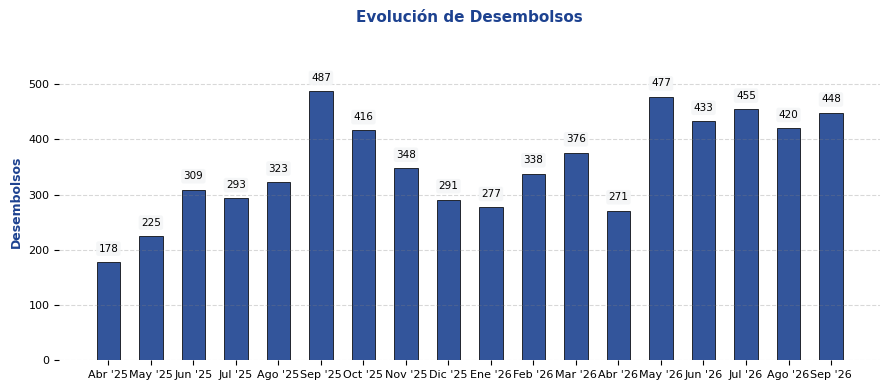

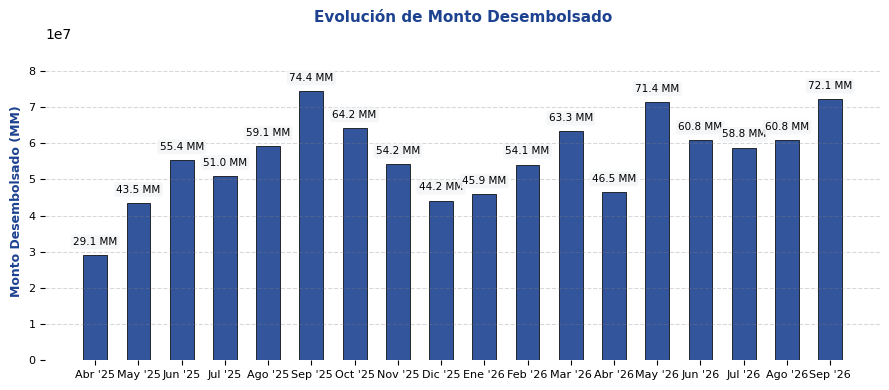

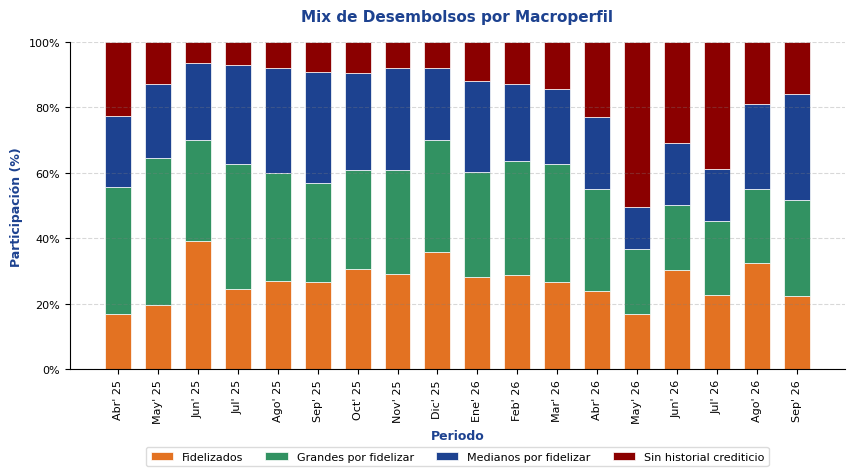

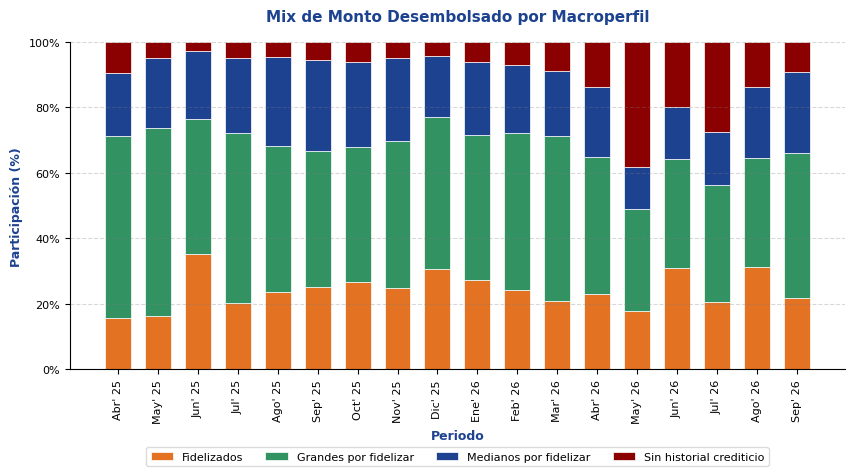

In [21]:
materialidad_mensual = panel.groupby('periodo').agg(
    desembolsos_ibk=('desembolsos_ibk', 'sum'), monto_desembolsado_ibk=('monto_desembolsado_ibk', 'sum'),
).reset_index()

plot_materialidad_por_mes(
    df=materialidad_mensual, col_periodo='periodo', col_valor='desembolsos_ibk',
    titulo='Evolución de Desembolsos', ylabel='Desembolsos', color_barras='#1D4290', es_monto=False,
)
plot_materialidad_por_mes(
    df=materialidad_mensual, col_periodo='periodo', col_valor='monto_desembolsado_ibk',
    titulo='Evolución de Monto Desembolsado', ylabel='Monto Desembolsado (MM)', color_barras='#1D4290', es_monto=True,
)
plot_participacion_panel(
    df=panel, columna_periodo='periodo', columna_grupo='macroperfil',
    metrica_materialidad='desembolsos_ibk', titulo='Mix de Desembolsos por Macroperfil',
)
plot_participacion_panel(
    df=panel, columna_periodo='periodo', columna_grupo='macroperfil',
    metrica_materialidad='monto_desembolsado_ibk', titulo='Mix de Monto Desembolsado por Macroperfil',
)

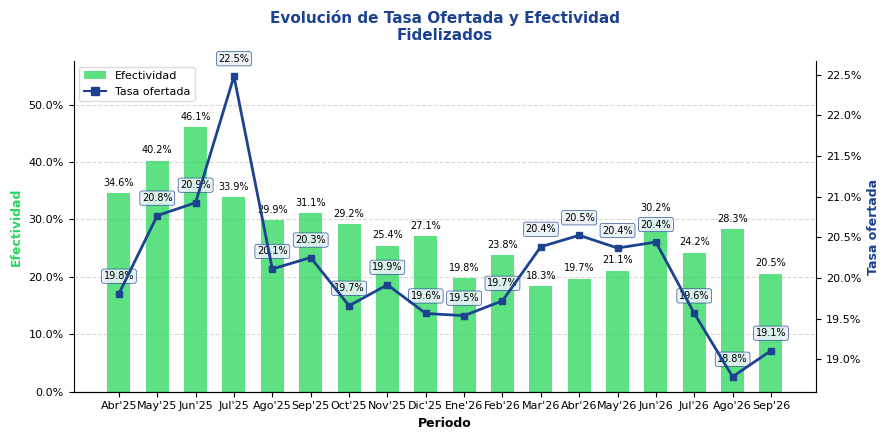

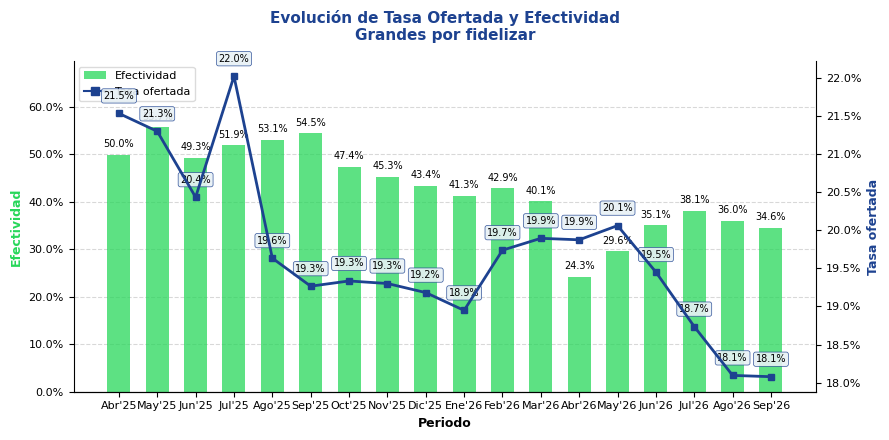

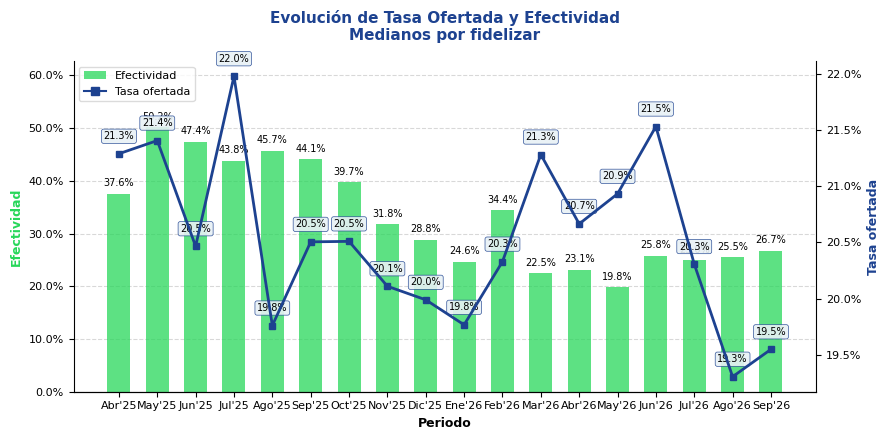

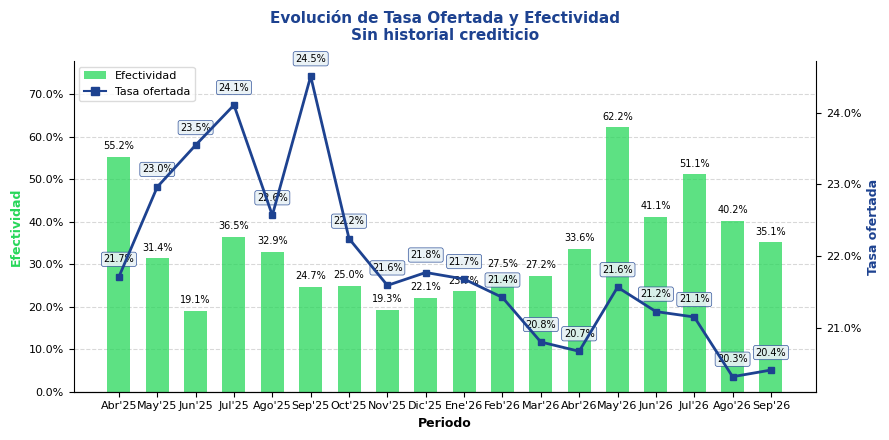

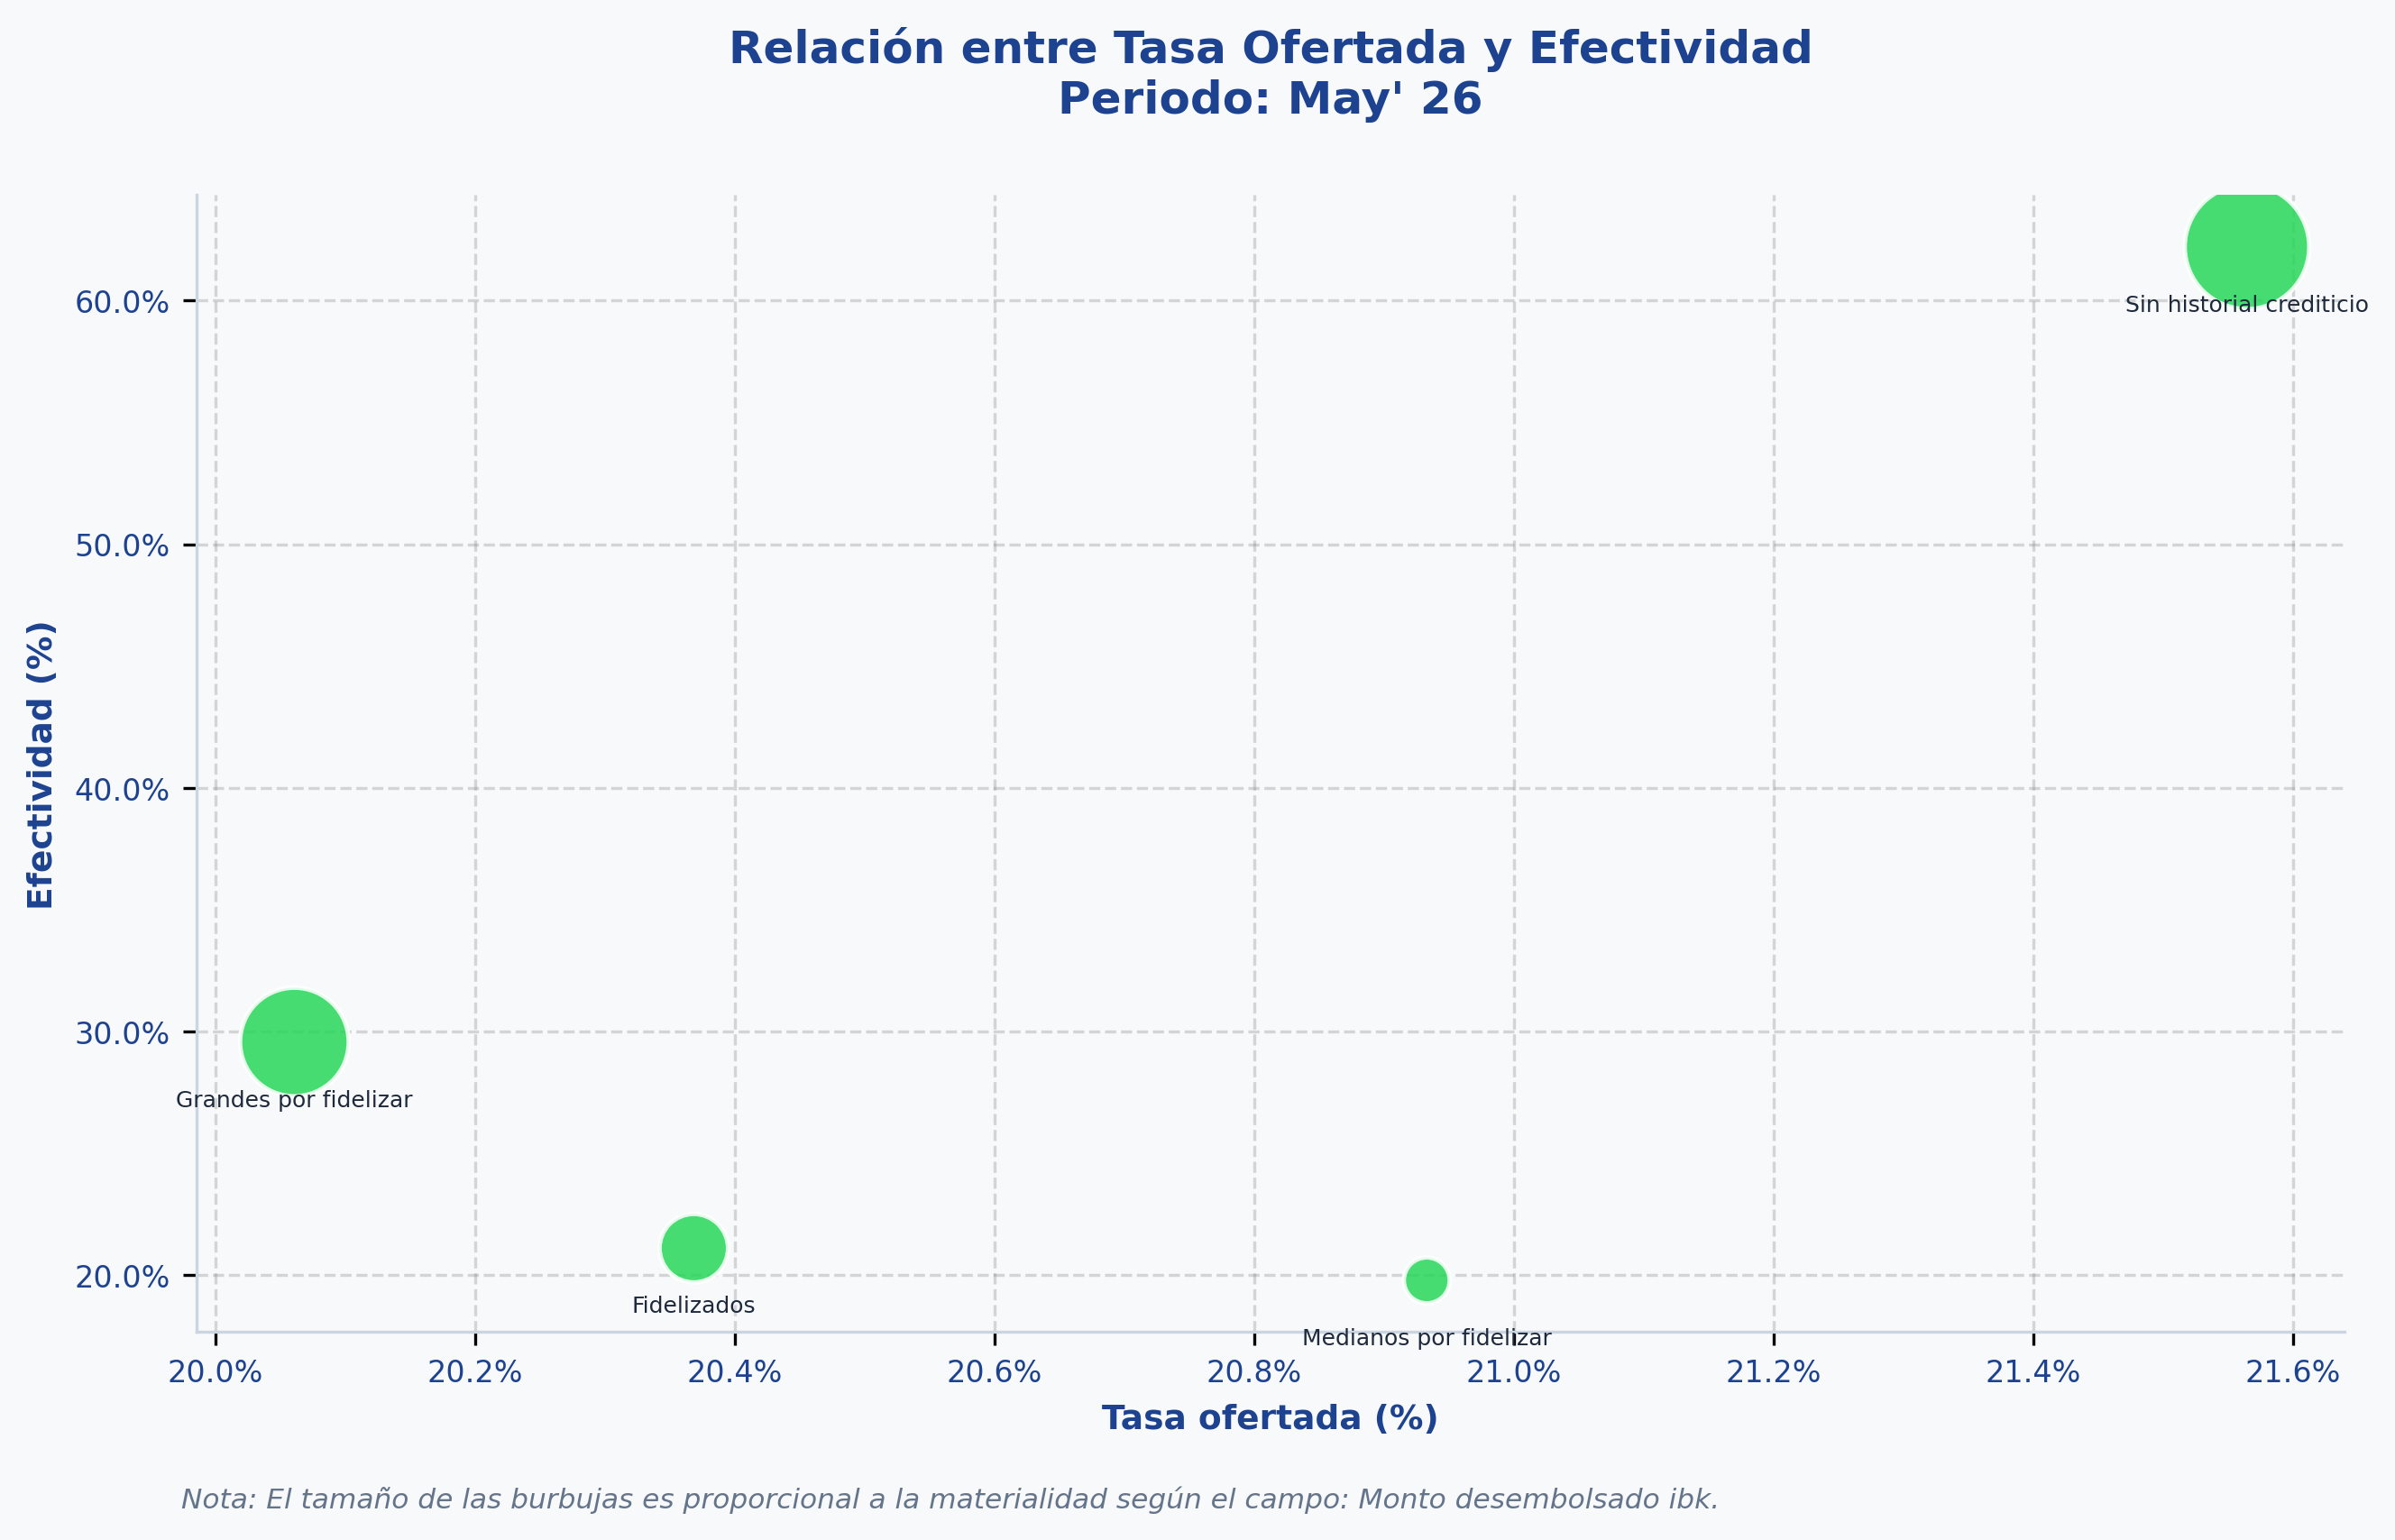

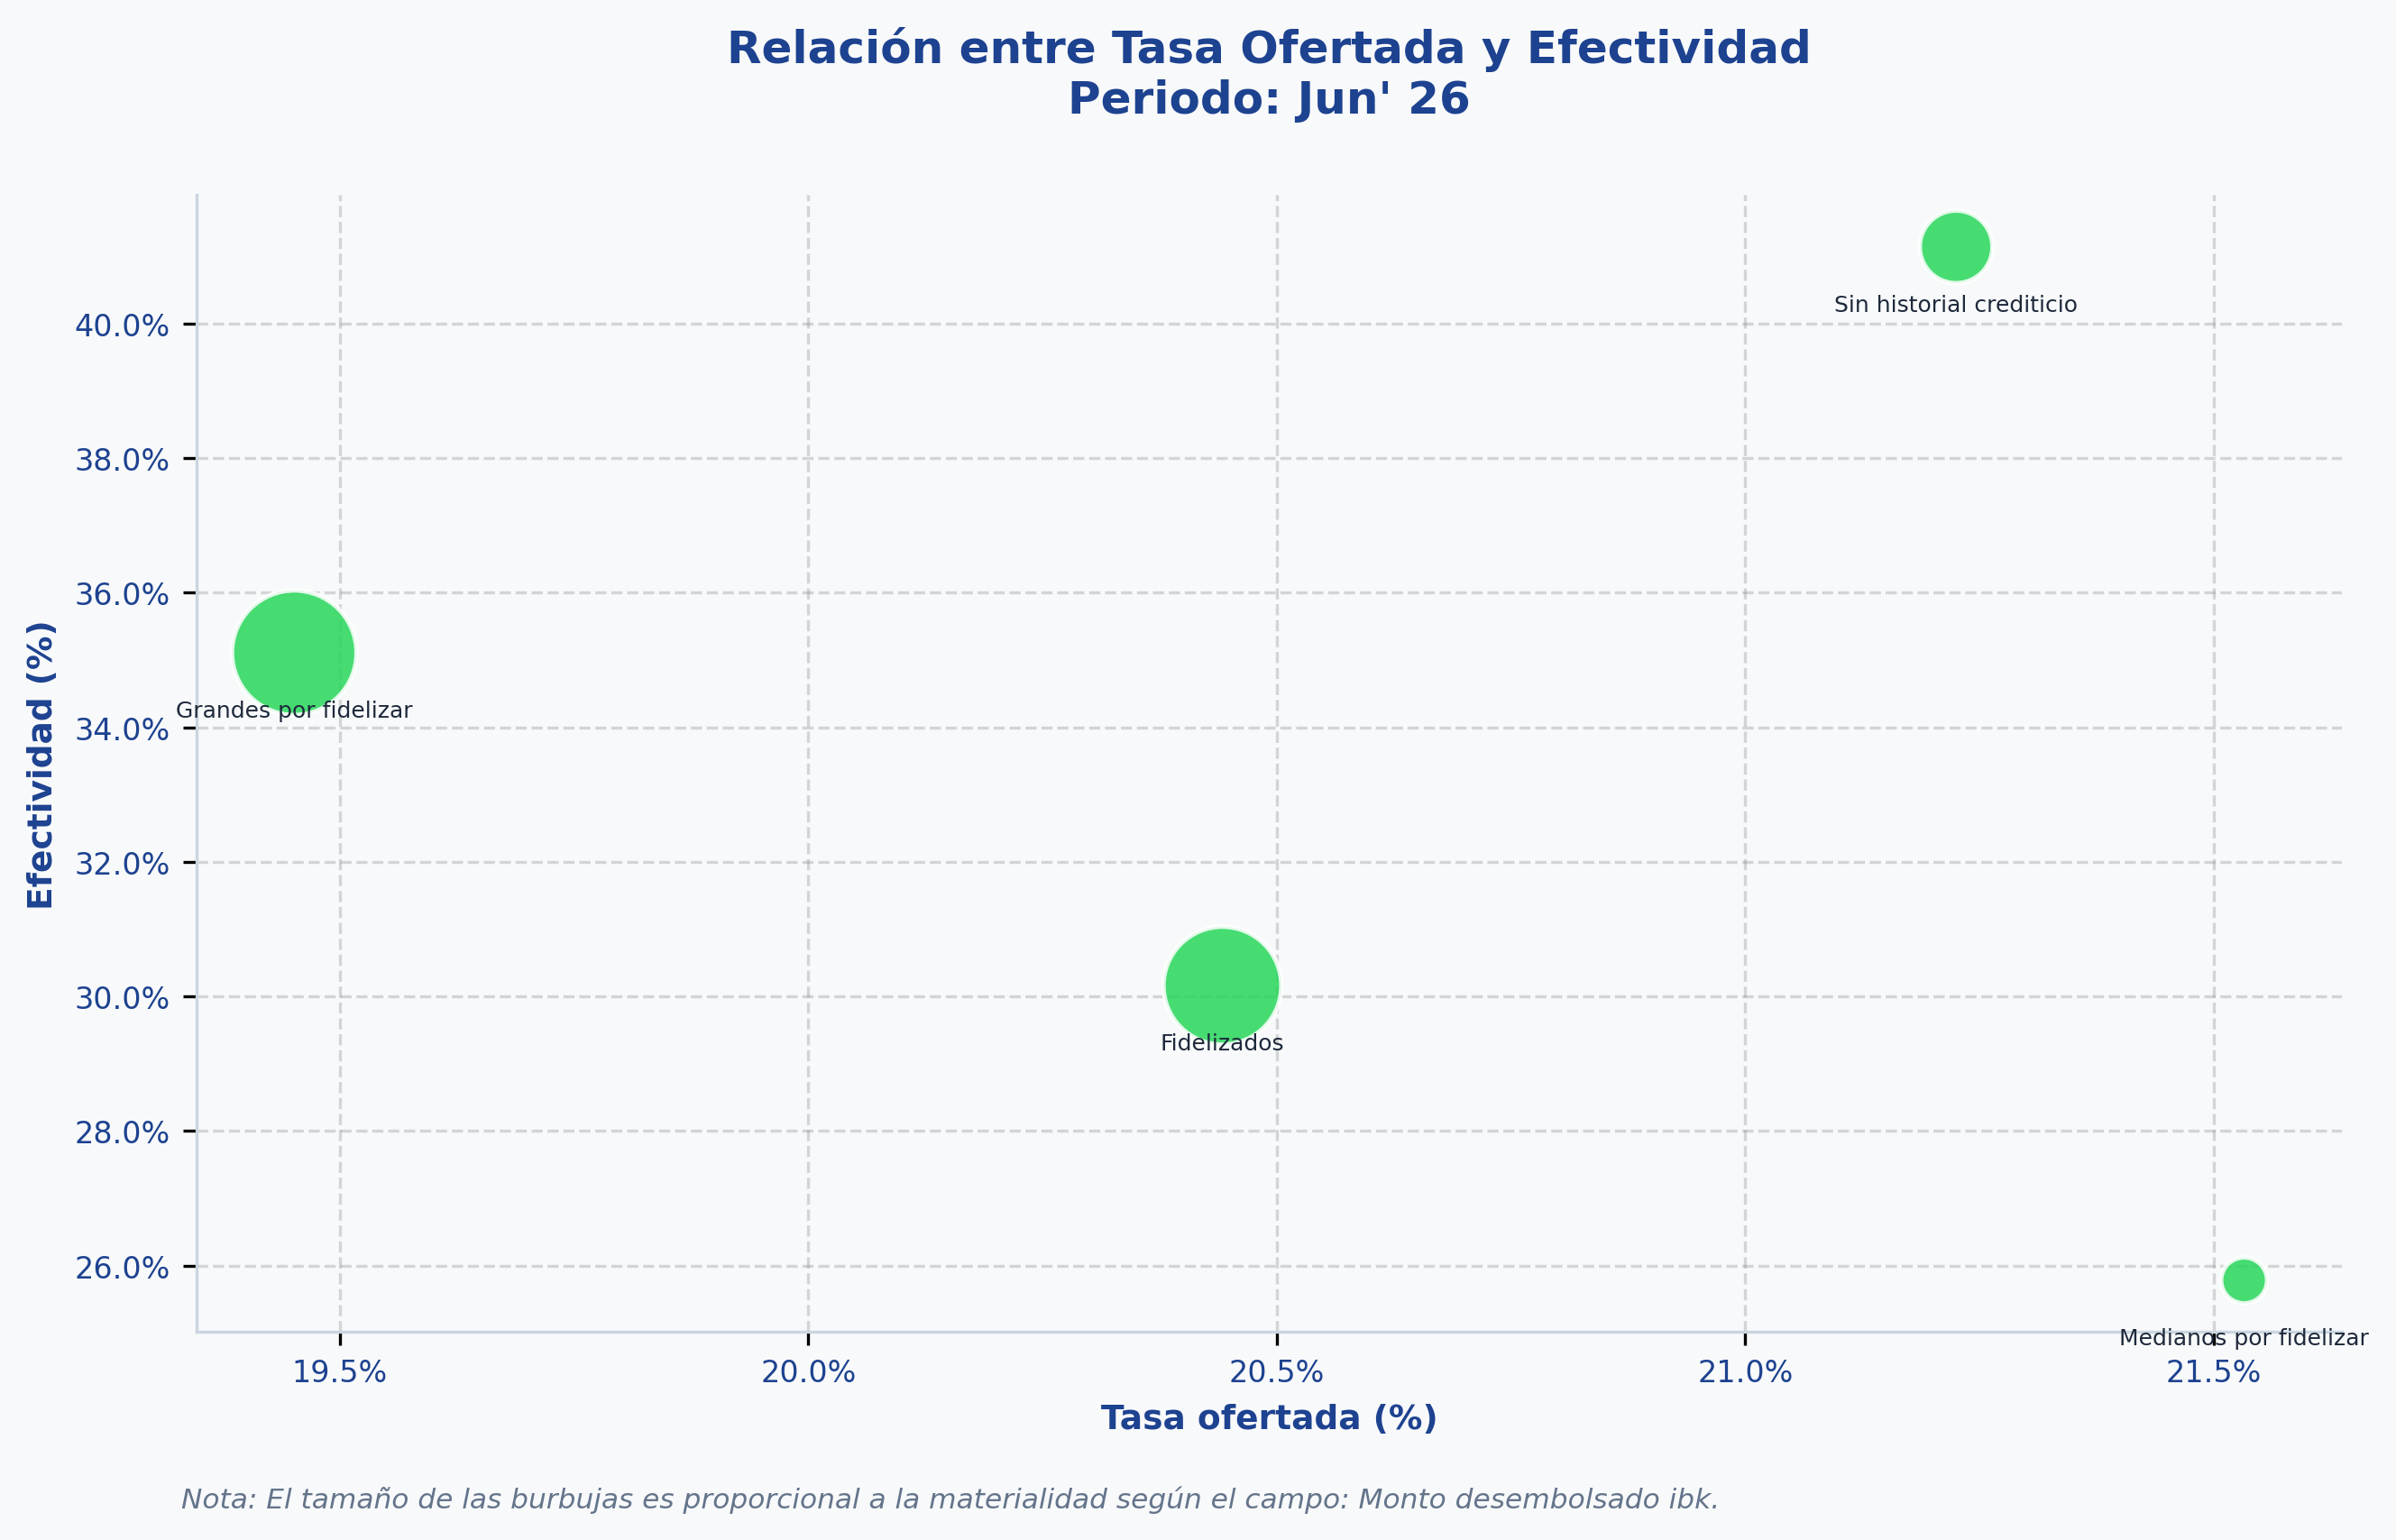

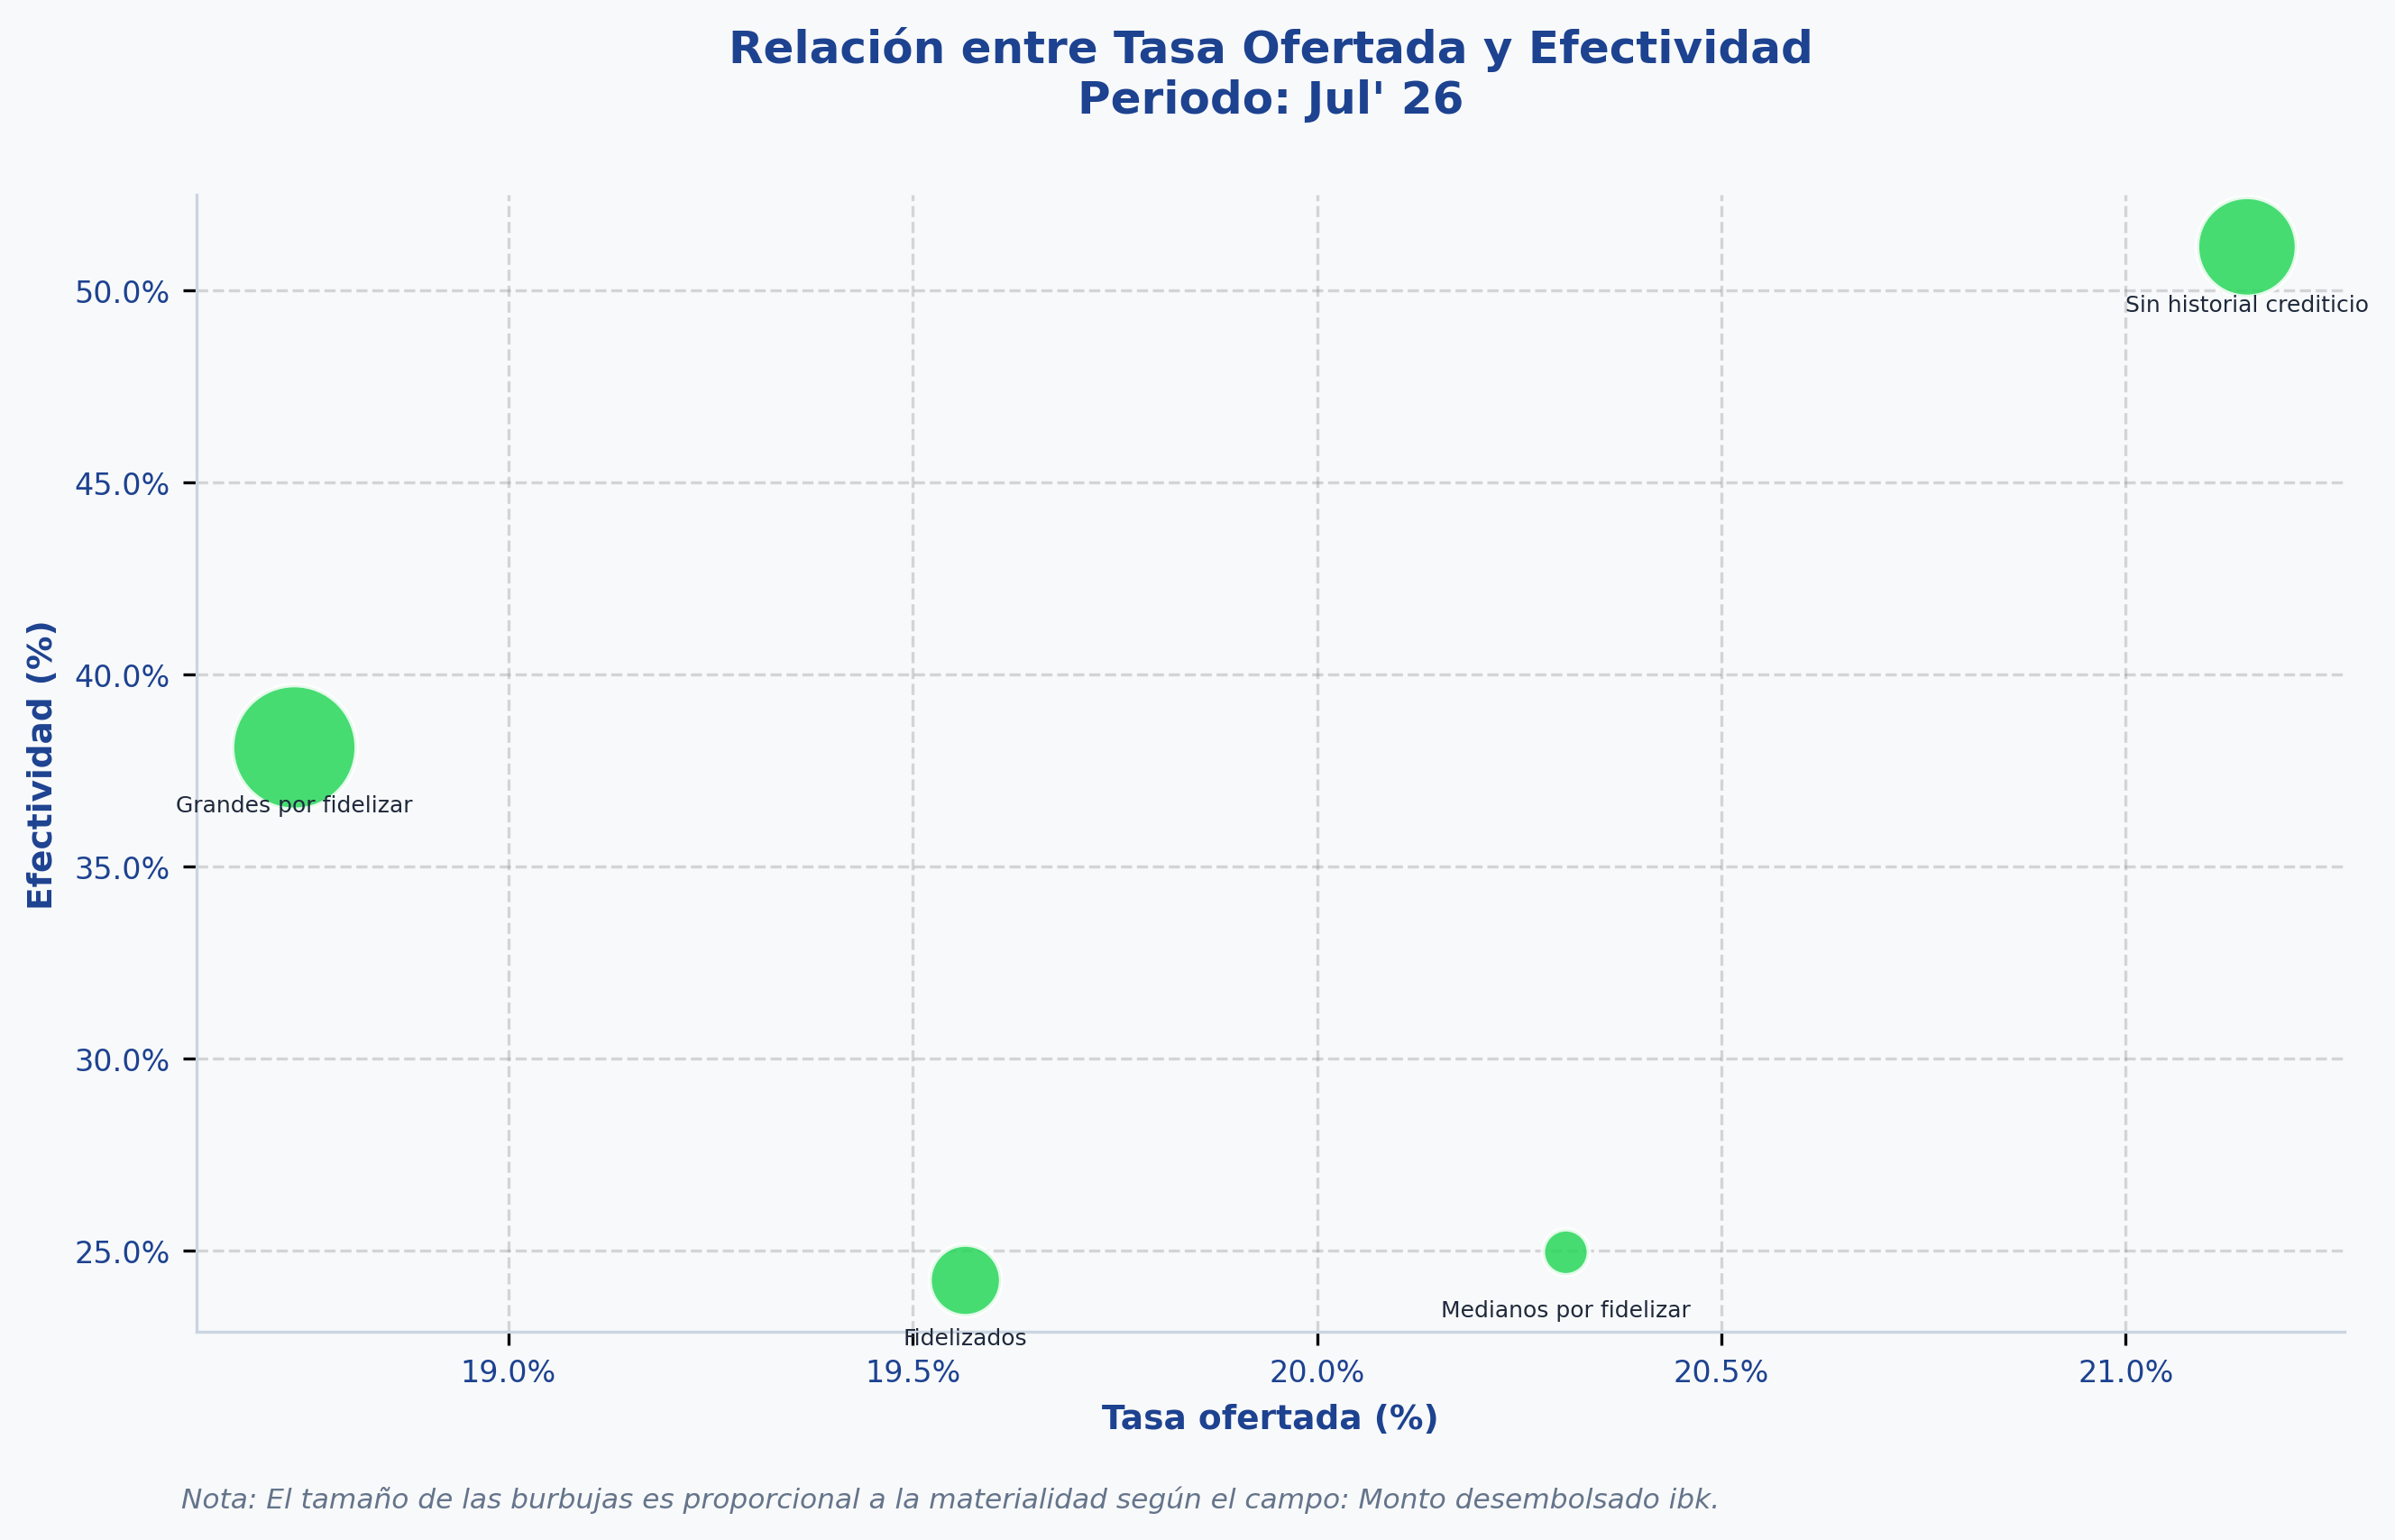

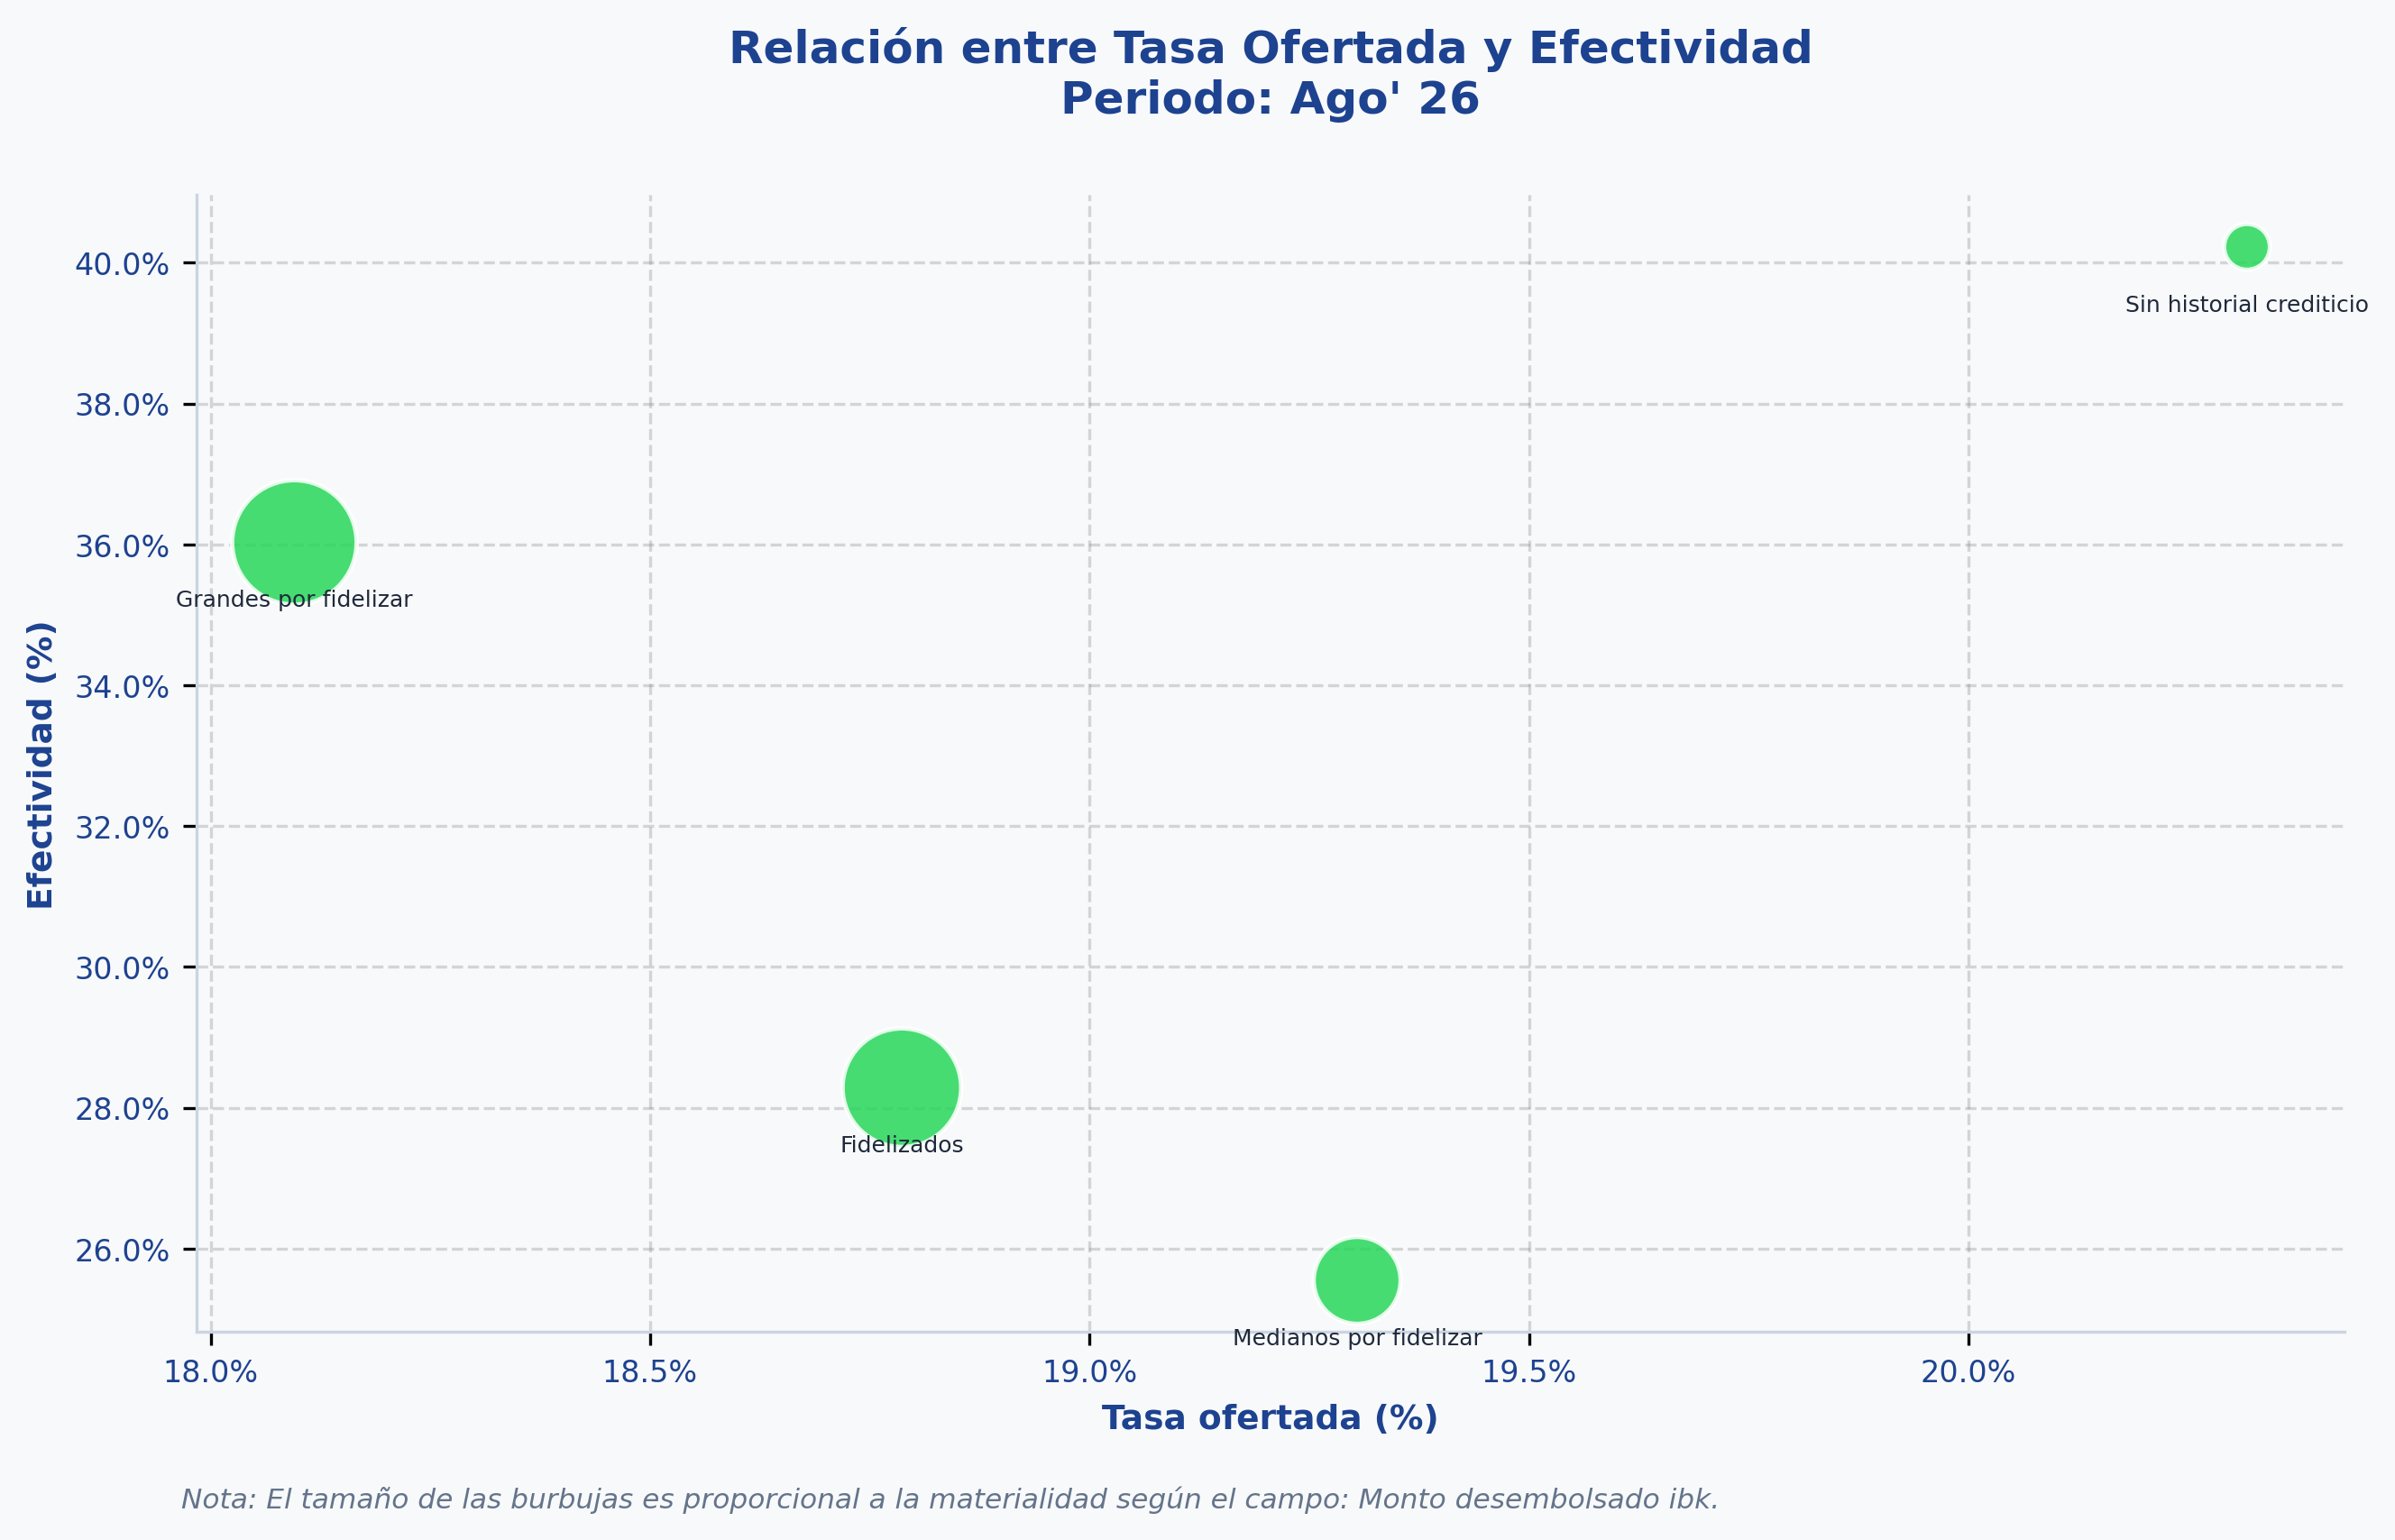

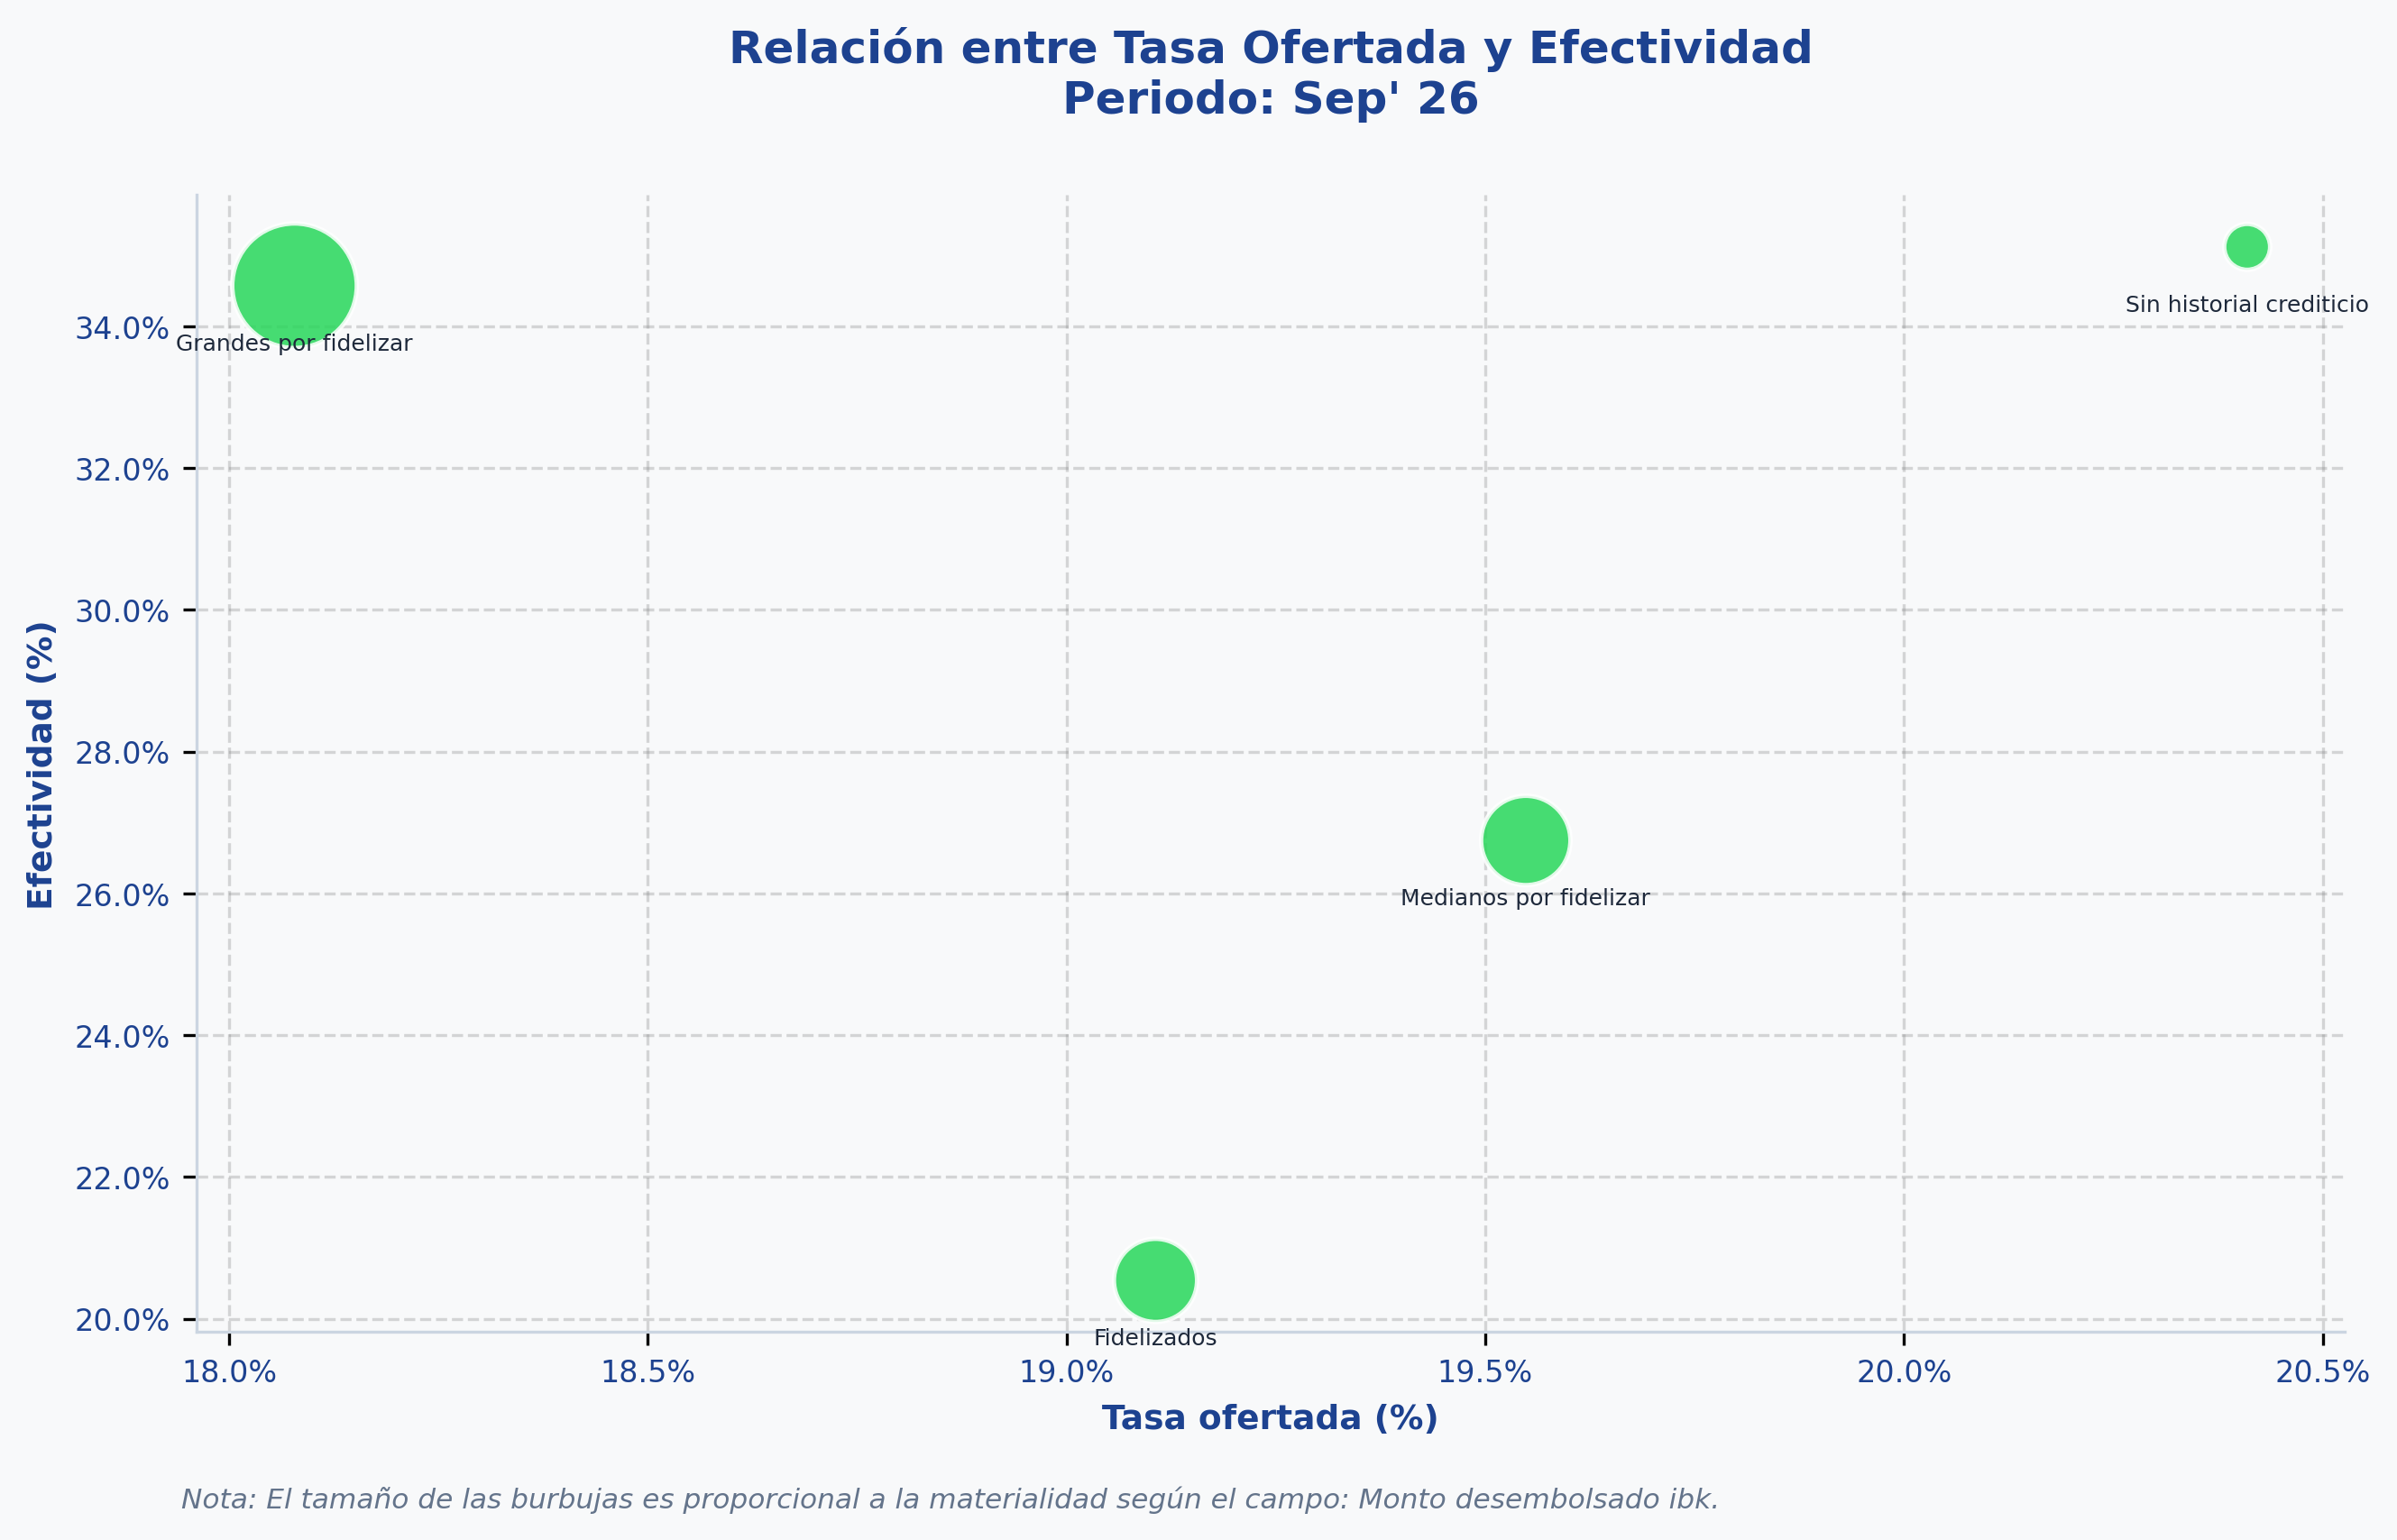

In [22]:
# Evolutivo tasa ofertada vs efectividad, un gráfico por macroperfil
for macroperfil in panel['macroperfil'].unique():
    plot_evolutivo_demanda_precio_barras(
        df=panel[panel['macroperfil'] == macroperfil],
        columna_demanda='efectividad', columna_precio='tasa_ofertada',
        titulo=f"Evolución de Tasa Ofertada y Efectividad\n{macroperfil}",
        flg_etiqueta_demanda=True, flg_etiqueta_precio=True,
    )

# Nube de puntos tasa vs efectividad por mes (tamaño = monto desembolsado)
MESES = {1: 'Ene', 2: 'Feb', 3: 'Mar', 4: 'Abr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Ago', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dic'}
PERIODO_INI_NUBE = 202605

for periodo in sorted(panel.loc[panel['periodo'] >= PERIODO_INI_NUBE, 'periodo'].unique()):
    etiqueta_periodo = f"{MESES[int(periodo) % 100]}' {str(int(periodo) // 100)[-2:]}"
    plot_nube_puntos_precio_demanda_interna(
        panel[panel['periodo'] == periodo],
        columna_precio='tasa_ofertada', columna_demanda='efectividad',
        columna_tamanio='monto_desembolsado_ibk', columna_cluster='macroperfil',
        titulo=f"Relación entre Tasa Ofertada y Efectividad\nPeriodo: {etiqueta_periodo}",
    )

### Modelo de panel con ventanas acumulativas

Se estima `log(efectividad) ~ log(tasa ofertada) × macroperfil` con **efectos fijos de
macroperfil y de mes** (`PanelOLS`) y errores agrupados por ambas dimensiones. El
coeficiente de cada interacción es la **elasticidad** del macroperfil. El modelo se
reestima con ventanas acumulativas hasta cada periodo de corte, de may-26 a set-26, para
ver cómo se mueven las elasticidades al agregar meses.

In [23]:
PERIODOS_CORTE = [202605, 202606, 202607, 202608, 202609]
SIGNIFICANCIA = 0.10


def preparar_panel_modelo(panel, periodo_corte):
    # panel en logs hasta el periodo de corte, con una interacción log(tasa) x macroperfil por bucket
    df = panel.loc[panel['periodo'] <= periodo_corte, ['macroperfil', 'periodo', 'efectividad', 'tasa_ofertada']].copy()
    df = df.rename(columns={'macroperfil': 'bucket'})
    df['mes'] = pd.to_datetime(df['periodo'].astype(int).astype(str), format='%Y%m')
    df = df[(df['efectividad'] > 0) & (df['tasa_ofertada'] > 0)].dropna(subset=['efectividad', 'tasa_ofertada']).copy()
    df['log_efectividad'] = np.log(df['efectividad'])
    df['log_tasa'] = np.log(df['tasa_ofertada'])
    df['bucket'] = df['bucket'].astype(str)

    interacciones = {}
    for i, bucket in enumerate(sorted(df['bucket'].unique())):
        columna = f'tasa_inter_{i}'
        df[columna] = df['log_tasa'] * (df['bucket'] == bucket).astype(int)
        interacciones[bucket] = columna
    return df, interacciones


def estimar_elasticidades(df, interacciones, periodo_corte):
    # PanelOLS con efectos fijos de entidad y tiempo, devuelve una fila por bucket
    df_panel = df.set_index(['bucket', 'mes']).sort_index()
    modelo = PanelOLS(
        dependent=df_panel['log_efectividad'], exog=df_panel[list(interacciones.values())],
        entity_effects=True, time_effects=True, drop_absorbed=True,
    )
    resultado = modelo.fit(cov_type='clustered', cluster_entity=True, cluster_time=True)
    intervalos = resultado.conf_int()

    tabla = pd.DataFrame([{
        'cluster': bucket,
        'elasticidad': resultado.params.get(columna, np.nan),
        'error_std': resultado.std_errors.get(columna, np.nan),
        'p_value': resultado.pvalues.get(columna, np.nan),
        'ic_inferior': intervalos.loc[columna, 'lower'],
        'ic_superior': intervalos.loc[columna, 'upper'],
    } for bucket, columna in interacciones.items()]).sort_values('cluster').reset_index(drop=True)

    tabla['significativo_10pct'] = tabla['p_value'] < SIGNIFICANCIA
    tabla['periodo'] = periodo_corte
    tabla['r2_overall'] = resultado.rsquared
    tabla['r2_within'] = resultado.rsquared_within
    tabla['r2_between'] = resultado.rsquared_between
    tabla['f_stat'] = resultado.f_statistic.stat
    tabla['f_pval'] = resultado.f_statistic.pval
    return resultado, tabla


resultados_rolling = []
for periodo_corte in PERIODOS_CORTE:
    df_modelo, interacciones = preparar_panel_modelo(panel, periodo_corte)
    print(f"\n--- Ventana hasta {periodo_corte}: {len(df_modelo):,} observaciones, "
          f"{df_modelo['bucket'].nunique()} macroperfiles, {df_modelo['mes'].nunique()} meses ---")
    try:
        resultado, tabla = estimar_elasticidades(df_modelo, interacciones, periodo_corte)
    except Exception as error:
        print(f"ADVERTENCIA: falló la estimación para {periodo_corte}: {error}")
        continue
    resultados_rolling.append(tabla)
    for _, fila in tabla.iterrows():
        print(f"{fila['cluster']}: elasticidad={fila['elasticidad']:.3f}, p={fila['p_value']:.3g}, "
              f"significativo al {SIGNIFICANCIA:.0%}={fila['significativo_10pct']}")

resultados_rolling = pd.concat(resultados_rolling, ignore_index=True)
resultados_rolling['flg_significativo'] = resultados_rolling['significativo_10pct'].astype(int)

# Detalle del último modelo estimado
print(resultado.summary)


--- Ventana hasta 202605: 56 observaciones, 4 macroperfiles, 14 meses ---
Fidelizados: elasticidad=-2.514, p=0.11, significativo al 10%=False
Grandes por fidelizar: elasticidad=-4.086, p=0.000838, significativo al 10%=True
Medianos por fidelizar: elasticidad=-4.614, p=0.0173, significativo al 10%=True
Sin historial crediticio: elasticidad=-5.901, p=5.1e-05, significativo al 10%=True

--- Ventana hasta 202606: 60 observaciones, 4 macroperfiles, 15 meses ---
Fidelizados: elasticidad=-2.302, p=0.187, significativo al 10%=False
Grandes por fidelizar: elasticidad=-3.694, p=0.00255, significativo al 10%=True
Medianos por fidelizar: elasticidad=-4.485, p=0.014, significativo al 10%=True
Sin historial crediticio: elasticidad=-6.024, p=7.3e-06, significativo al 10%=True

--- Ventana hasta 202607: 64 observaciones, 4 macroperfiles, 16 meses ---
Fidelizados: elasticidad=-2.059, p=0.179, significativo al 10%=False
Grandes por fidelizar: elasticidad=-3.174, p=0.00195, significativo al 10%=True
Med

### Validación: significancia y evolución de las elasticidades

Se revisa en qué ventanas cada elasticidad es significativa al 10% y cómo evoluciona su
valor al agregar meses.

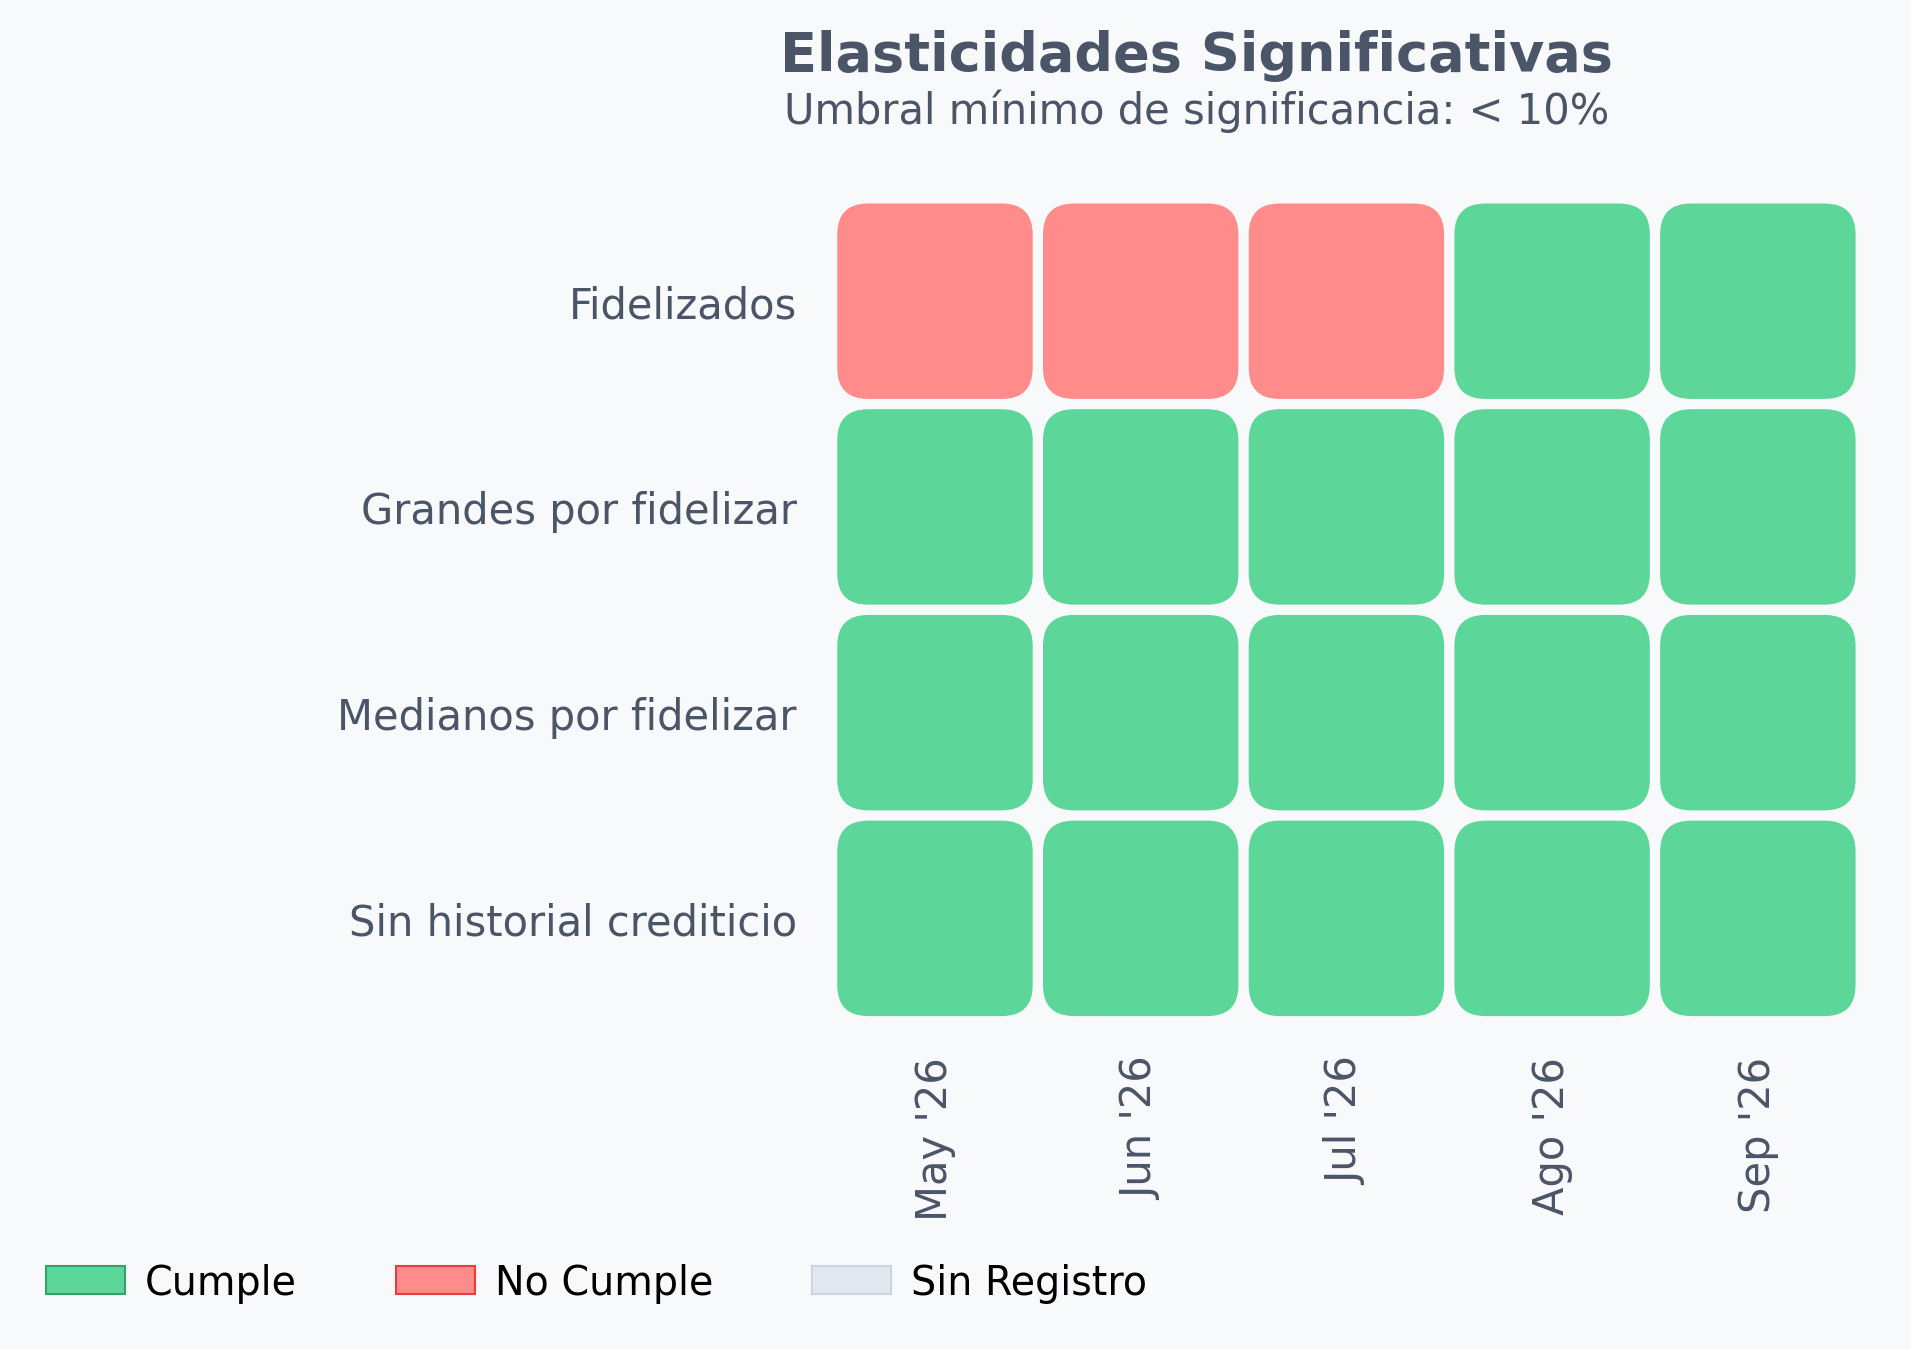

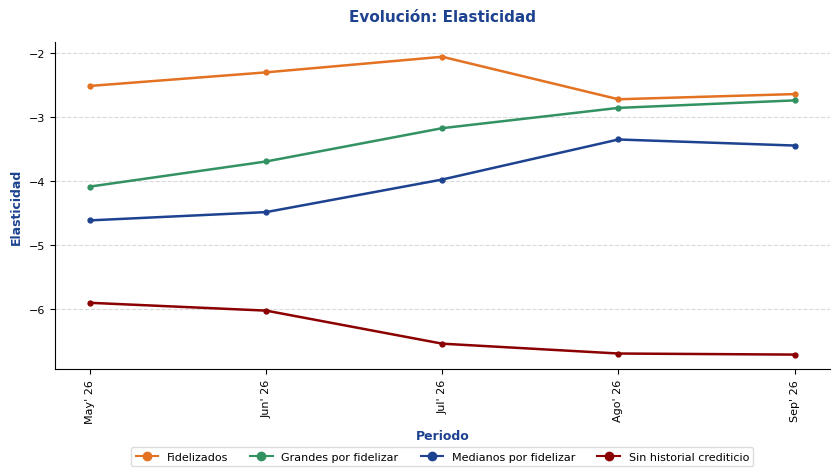

In [24]:
plot_heatmap_cumplimiento(
    df_panel=resultados_rolling, col_cluster='cluster', col_periodo='periodo', col_flag='flg_significativo',
    titulo='Elasticidades Significativas', subtitulo=f'Umbral mínimo de significancia: < {SIGNIFICANCIA:.0%}',
)
plot_evolutivo_multiserie_panel(
    df=resultados_rolling, columna_periodo='periodo', columna_grupo='cluster', metrica='elasticidad',
    multiplicar_100=False, label_metrica='Elasticidad', titulo='Evolución: Elasticidad',
)

### Monitoreo de estabilidad (gráficos de control I-MR)

Se monitorea la estabilidad de cada elasticidad a través de las ventanas sucesivas con
**gráficos de control I-MR** (Shewhart): el gráfico de individuales detecta cambios de
nivel y el de rangos móviles cambios de volatilidad. Los límites se construyen con la
variabilidad histórica (constantes 2,66 y 3,267), y una elasticidad fuera de los límites
es una alerta de que el parámetro de pricing dejó de ser estable.

In [25]:
A2_MR = 2.66    # constante para límites de individuales
D4 = 3.267      # constante para el límite superior de rangos móviles
COLOR_AZUL, COLOR_ROJO = '#1D4290', '#E63946'


def calcular_limites_imr(data, variable='elasticidad'):
    # límites de control I-MR y alertas para una serie de elasticidades por ventana
    data = data.sort_values('periodo').copy()
    if len(data) < 2:
        return None
    data['MR'] = data[variable].diff().abs()
    media, mr_promedio = data[variable].mean(), data['MR'].mean()
    data['LC_I'], data['LSC_I'], data['LIC_I'] = media, media + A2_MR * mr_promedio, media - A2_MR * mr_promedio
    data['LC_MR'], data['LSC_MR'], data['LIC_MR'] = mr_promedio, D4 * mr_promedio, 0.0
    data['alerta_I'] = (data[variable] > data['LSC_I']) | (data[variable] < data['LIC_I'])
    data['alerta_MR'] = data['MR'] > data['LSC_MR']
    return data


def _estilo_control(ax, x, etiquetas, titulo):
    # formato común de los gráficos de control
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#CCCCCC')
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas, fontsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_title(titulo, fontsize=11, fontweight='bold', color=COLOR_AZUL, pad=15)
    ax.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='lightgray', fontsize=7.5)


def _anotar_valores(ax, x, valores, alertas):
    # etiqueta cada punto, en rojo si está fuera de control
    for xi, valor, alerta in zip(x, valores, alertas):
        ax.annotate(f'{valor:.3f}', (xi, valor), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=7,
                    bbox=dict(boxstyle='round,pad=0.2', fc='#FADBD8' if alerta else '#E8F1F5',
                              ec=COLOR_ROJO if alerta else COLOR_AZUL, lw=0.8, alpha=0.9))


def graficar_tendencia(data, cluster, variable='elasticidad'):
    # gráfico de individuales: nivel de la elasticidad por ventana con límites LC / LSC / LIC
    data = data.sort_values('periodo').copy()
    x = np.arange(len(data))
    etiquetas = pd.to_datetime(data['periodo'].astype(int).astype(str), format='%Y%m').dt.strftime('%b-%y').values

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x, data[variable], color=COLOR_AZUL, marker='o', markersize=5, linewidth=1.8, label='Elasticidad estimada', zorder=3)
    ax.axhline(data['LC_I'].iloc[0], color='#555555', linewidth=1.2, label=f"LC ({data['LC_I'].iloc[0]:.3f})")
    for limite, nombre in [('LSC_I', 'LSC'), ('LIC_I', 'LIC')]:
        ax.axhline(data[limite].iloc[0], color=COLOR_ROJO, linestyle='--', linewidth=1.2, label=f"{nombre} ({data[limite].iloc[0]:.3f})")
    alertas = data['alerta_I'].to_numpy()
    if alertas.any():
        ax.scatter(x[alertas], data.loc[alertas, variable], color=COLOR_ROJO, marker='X', s=90, zorder=4, label='Fuera de control')
    _anotar_valores(ax, x, data[variable], alertas)
    _estilo_control(ax, x, etiquetas, f'Monitoreo de Estabilidad de Elasticidad | {cluster}')
    plt.tight_layout()
    plt.show()


def graficar_volatilidad(data, cluster):
    # gráfico de rangos móviles: variación absoluta entre ventanas con límite LSC
    data = data.sort_values('periodo').dropna(subset=['MR']).copy()
    x = np.arange(1, len(data) + 1)
    etiquetas = pd.to_datetime(data['periodo'].astype(int).astype(str), format='%Y%m').dt.strftime('%b-%y').values

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x, data['MR'], color=COLOR_AZUL, marker='o', markersize=5, linewidth=1.8, label='Variación absoluta entre ventanas', zorder=3)
    ax.axhline(data['LC_MR'].iloc[0], color='#555555', linewidth=1.2, label=f"LC ({data['LC_MR'].iloc[0]:.3f})")
    ax.axhline(data['LSC_MR'].iloc[0], color=COLOR_ROJO, linestyle='--', linewidth=1.2, label=f"LSC ({data['LSC_MR'].iloc[0]:.3f})")
    ax.axhline(data['LIC_MR'].iloc[0], color='#555555', linestyle=':', linewidth=1)
    alertas = data['alerta_MR'].to_numpy()
    if alertas.any():
        ax.scatter(x[alertas], data.loc[alertas, 'MR'], color=COLOR_ROJO, marker='X', s=90, zorder=4, label='Alerta por volatilidad')
    _anotar_valores(ax, x, data['MR'], alertas)
    _estilo_control(ax, x, etiquetas, f'Monitoreo de Volatilidad y Cambios (MR) | {cluster}')
    plt.tight_layout()
    plt.show()

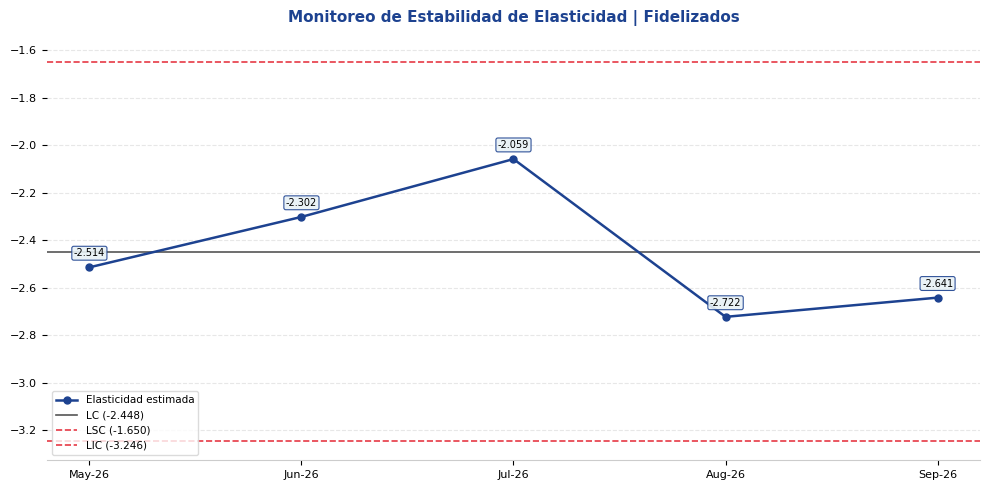

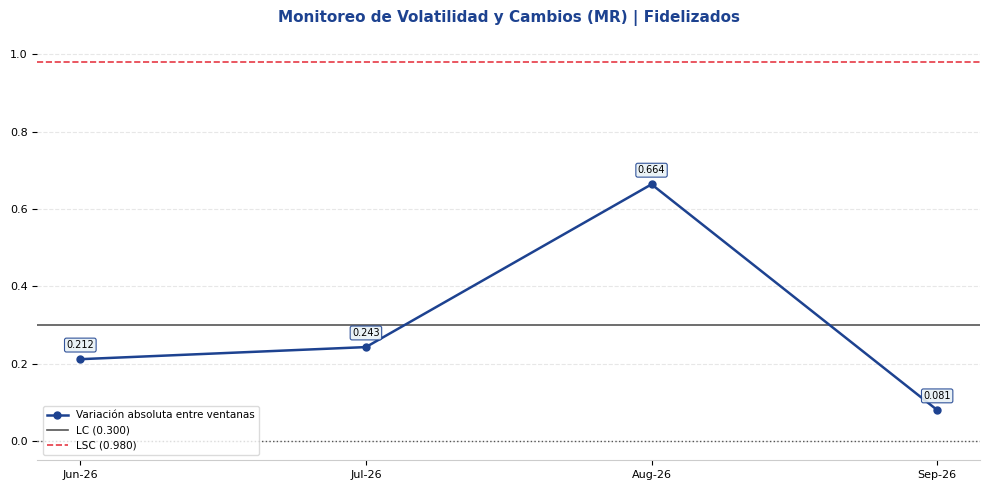

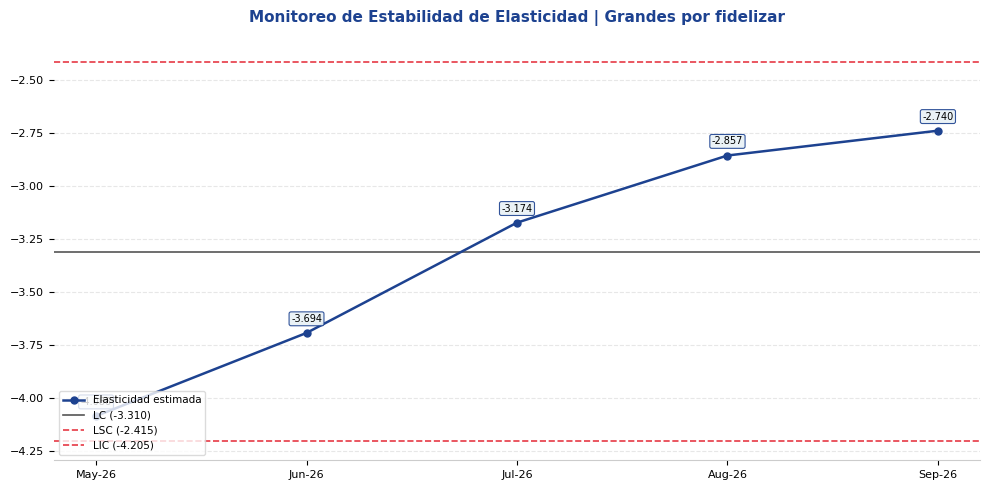

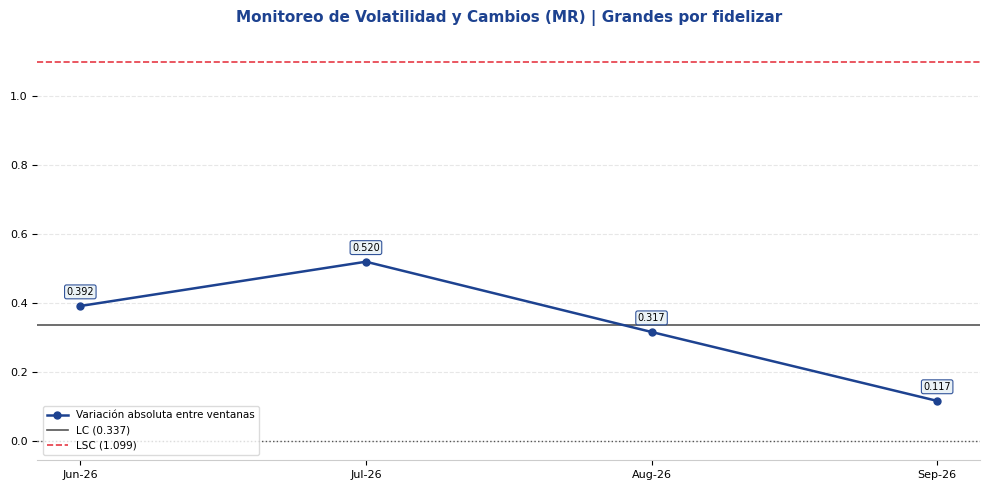

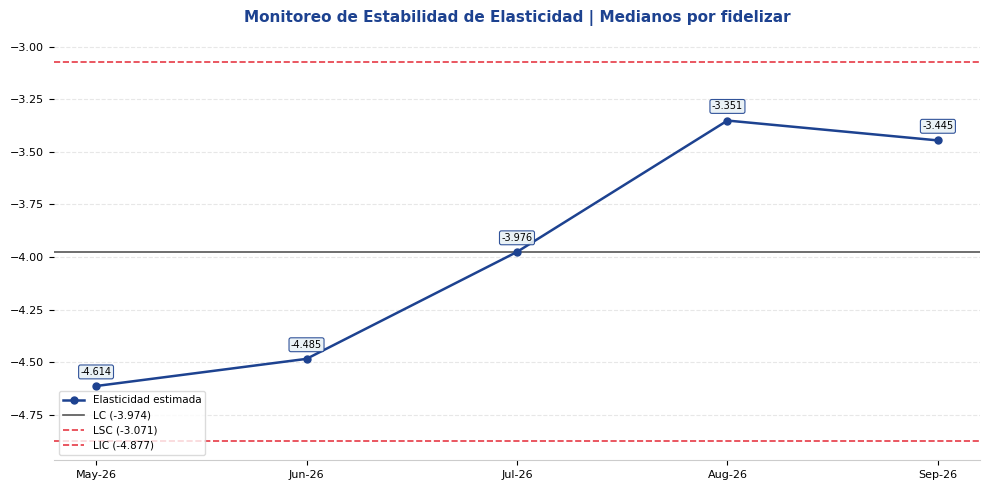

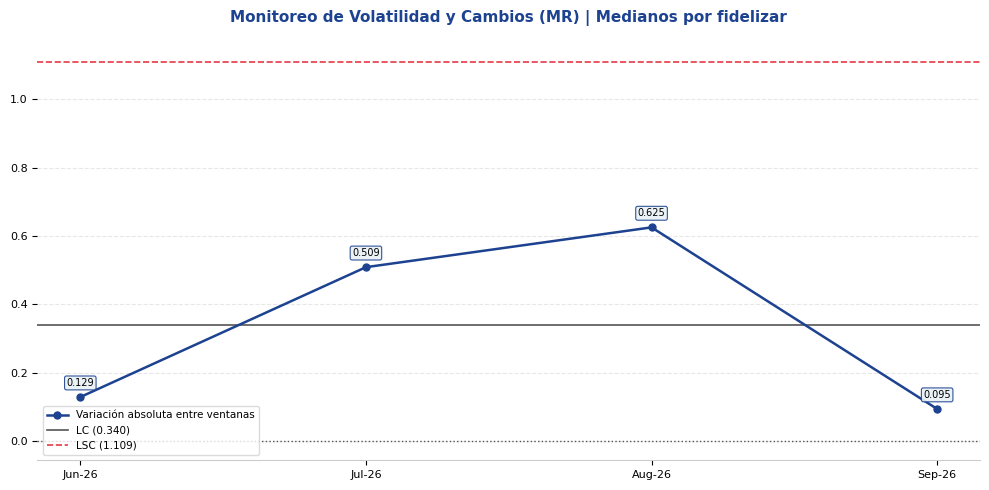

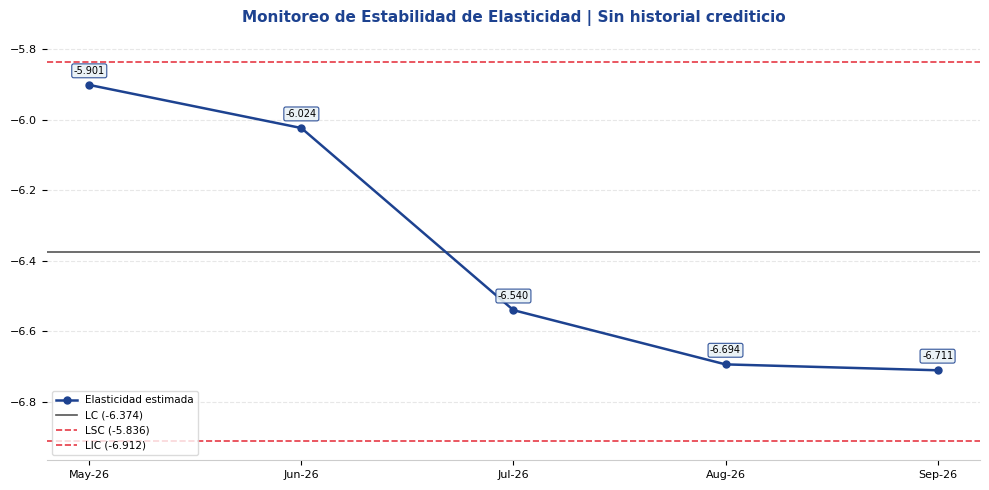

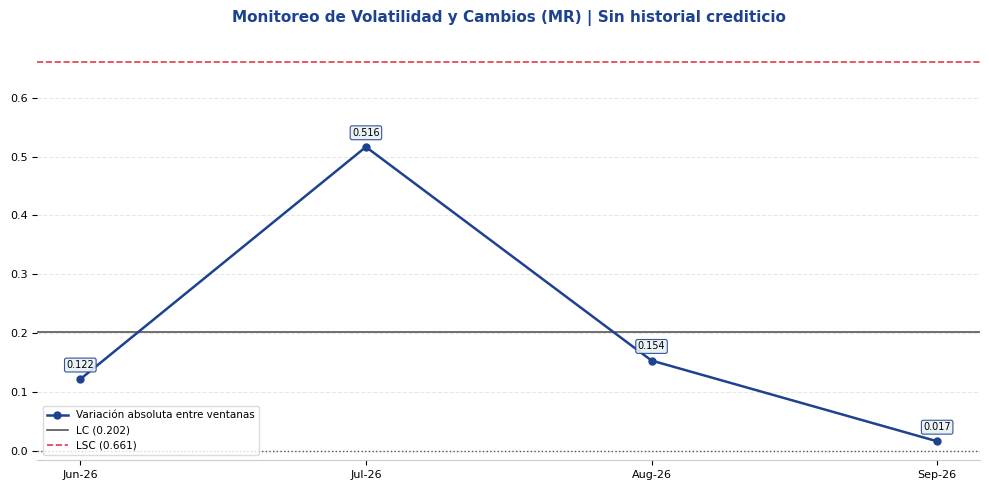

Alertas de control por macroperfil:
                          alerta_I  alerta_MR
cluster                                      
Fidelizados                      0          0
Grandes por fidelizar            0          0
Medianos por fidelizar           0          0
Sin historial crediticio         0          0


In [26]:
df_control = (
    resultados_rolling[['cluster', 'periodo', 'elasticidad']]
    .dropna()
    .sort_values(['cluster', 'periodo'])
)

resultados_control = []
for cluster, data in df_control.groupby('cluster'):
    data_control = calcular_limites_imr(data)
    if data_control is None:
        print(f"{cluster}: observaciones insuficientes para el control I-MR")
        continue
    resultados_control.append(data_control)
    graficar_tendencia(data_control, cluster)
    graficar_volatilidad(data_control, cluster)

resultados_control = pd.concat(resultados_control, ignore_index=True)
print("Alertas de control por macroperfil:")
print(resultados_control.groupby('cluster')[['alerta_I', 'alerta_MR']].sum().astype(int).to_string())